# Credit Pre-Screening Engine — Loan Intake Optimisation
**Role:** Credit Policy Analyst  |  **Industry:** Banking (Retail Lending)

## Problem Statement
- A private bank gives **personal loans** to customers across India.
- It gets about **3,000 loan applications every month**.
- **Every application** is checked by a human analyst. One check takes about **25 minutes**. That is about **1,250 hours of work every month**.
- Nearly **half of the applications are declined**. Many of them are easy "no" cases, for example a very low credit score, or EMIs that already eat most of the income.

The bank receives a large number of loan applications and needs an efficient way to identify applications that can be automatically declined, fast-tracked for approval, or sent for manual review. Currently, many applications require human analyst attention, increasing processing time and operational workload.

The objective of this use case is to build a machine-learning-based credit policy pre-screener that classifies loan applications into three categories:

1. Auto-decline: Applications with very high confidence that the bank's historical credit policy would decline them.

2. Fast-track: Applications with very high confidence that the bank's historical credit policy would approve them, subject to a light-touch verification check.

3. Manual review: Applications that require further investigation and human analyst judgment.

The analysis will begin by examining historical application data to understand existing approval patterns, identify data quality issues, engineer affordability-related features, and investigate the factors associated with loan approval or decline. It will then develop and compare classification models, evaluate their performance, examine fairness-related differences, and establish confidence thresholds for assigning applications to the three categories.

The main objective is not simply to maximize model accuracy. It is to reduce manual review workload while minimizing the risk of wrongly rejecting good applicants or automatically fast-tracking risky applicants. The final recommendation should balance operational efficiency, prediction reliability, explainability, fairness, and the need for human oversight in uncertain cases.

## What We Will Do in This Notebook

- Clean the dataset and understand which factors influence loan approvals.
- Build a baseline Logistic Regression model and select a safe threshold for automatic declines.
- Check whether approval patterns and model decisions differ between men and women.
- Compare four machine-learning models and select the most suitable one.
- Build a two-lane pre-screening system with **Auto-decline**, **Fast-track**, and manual review for all remaining applications.
- Recommend the best approach and estimate the monthly reduction in manual reviews and analyst working hours.
- **Optional (Extra Credit):** Use K-Means clustering to group applicants and identify segments where the model makes more prediction errors.

## Tools Used

- **Python and Jupyter Notebook** — to write and run the analysis.
- **Pandas and NumPy** — to load, clean, and analyse the data.
- **Matplotlib and Seaborn** — to create graphs such as bar charts, boxplots, and heatmaps.
- **Scikit-learn** — to build, compare, and evaluate machine-learning models.

## Dataset Information

- **File name:** `MUC02_Credit_PreScreening_Dataset.csv`
- **File location:** Keep the CSV file in the same folder as the Jupyter Notebook.
- **Number of records:** 12,000 loan applications.
- **Time period:** April to September 2026.
- **Each row:** Represents one loan application.
- **Target column:** `decision`, which contains the historical credit team's final decision — `Approved` or `Declined`.

The model will learn patterns from historical credit decisions to help identify applications suitable for automated routing while keeping uncertain applications for human review.

# CBIM — Credit Pre-Screening Engine

### 1. Situation (S)

The bank is a mid-sized private bank in India that processes around 3,000 personal loan applications every month. Currently, credit analysts manually review applications, taking approximately 25 minutes per application to make a lending decision.

### 2. Complication (C)

Manual reviews consume significant analyst time, even for applications that are clearly likely to be declined or approved. This increases the bank's workload, leaves less time for applications that need careful judgment, and may delay decisions for applicants.

### 3. Question (Q)

Can a pre-screening model help the bank identify applications suitable for **automatic decline** or **fast-track approval checks**, while sending uncertain applications to manual review? The goal is to reduce manual workload without incorrectly rejecting applicants who would historically have been approved or fast-tracking applicants who would historically have been declined.

### 4. SSOT (Single Source of Truth)

The single source of truth is the dataset `MUC02_Credit_PreScreening_Dataset.csv`, containing 12,000 personal loan applications from April to September 2026. Each row represents one application, and the `decision` column records the historical credit team's final decision: `Approved` or `Declined`. This historical decision is the target used to train and evaluate the model.

### 5. Success Definition

The pre-screener must satisfy both of the bank's risk limits:

- **Auto-decline lane:** No more than 5% of applications routed to this lane should have been historically approved.
- **Fast-track lane:** No more than 5% of applications routed to this lane should have been historically declined.

The model should meet these limits while reducing the number of applications requiring manual review. The reduction in manual reviews and estimated analyst hours saved per month will be used to assess the operational benefit.

### 6. Primary Stakeholder

The primary stakeholder is the **Credit Policy Analyst**, who needs to recommend a safe and practical pre-screening approach to the bank. Credit analysts, the credit policy team, the bank, and loan applicants are also affected because the system influences review workload, processing time, and how applications are routed. The model supports the process; it does not replace final human judgment for uncertain cases.


## Part 1 — Baseline Pre-Screener

### Step 5.1: Load, Inspect and Clean the Dataset

In [1]:

# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set a colourful style for the graphs
sns.set_theme(style="whitegrid", palette="Set2")

# Load the dataset
df = pd.read_csv(r"C:\Calibo\MUCO2\MUC02_Credit_PreScreening_Dataset.csv")

# Display the first five rows
df.head()


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


In [2]:

# Check the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 12000
Number of columns: 19


In [3]:

# Check the data type of every column
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  object 
 1   application_date       12000 non-null  object 
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  object 
 4   city                   12000 non-null  object 
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  object 
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  object 
 15  lo

In [4]:

# Count missing values in each column
missing_values = df.isnull().sum()

# Show only columns that contain missing values
print(missing_values[missing_values > 0])


monthly_income     441
credit_score      1039
dtype: int64


In [5]:

# Calculate missing values and their percentages
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

# Display columns that contain missing values
missing_summary = missing_summary[missing_summary["Missing Count"] > 0]

missing_summary.round(2)


,Missing Count,Missing Percentage
monthly_income,441,3.68
credit_score,1039,8.66


In [6]:

# Count each type of loan decision
decision_counts = df["decision"].value_counts()

# Calculate the percentage of each decision
decision_percentages = df["decision"].value_counts(normalize=True) * 100

# Combine the counts and percentages into one table
decision_summary = pd.DataFrame({
    "Application Count": decision_counts,
    "Percentage": decision_percentages
})

print(decision_summary.round(2))

# Calculate the overall approval rate
approval_rate = (df["decision"] == "Approved").mean() * 100

print(f"\nOverall Approval Rate: {approval_rate:.2f}%")


          Application Count  Percentage
decision                               
Approved               6353       52.94
Declined               5647       47.06

Overall Approval Rate: 52.94%


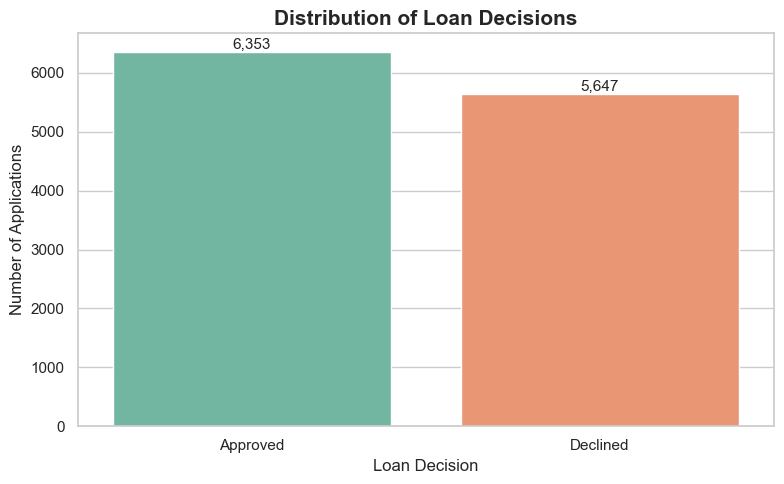

In [7]:

# Count approved and declined applications
decision_counts = df["decision"].value_counts()

# Create a colourful bar chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=decision_counts.index,
    y=decision_counts.values,
    hue=decision_counts.index,
    legend=False,
    palette=["#66C2A5", "#FC8D62"]
)

# Add labels on top of the bars
for bar in ax.patches:
    ax.annotate(
        f"{int(bar.get_height()):,}",
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha="center",
        va="bottom",
        fontsize=11
    )

plt.title("Distribution of Loan Decisions", fontsize=15, fontweight="bold")
plt.xlabel("Loan Decision")
plt.ylabel("Number of Applications")
plt.tight_layout()
plt.show()


### Checking Missing Monthly Income

Monthly income is important because it helps the bank understand whether an applicant can afford loan repayments. Missing income values must be investigated before they are filled.

I will check which employment types have the most missing income values. I will also compare the missing values across employment types to choose a suitable method for filling them.

For this analysis, the median income within each employment type is a reasonable starting point because income values can vary widely and may contain unusually high values. I will investigate the unusually high values before applying the final cleaning decision.

Missing monthly income by employment type:
employment_type
Business Owner                227
Self-Employed Professional    154
Salaried                       49
Gig / Contract                 11
dtype: int64


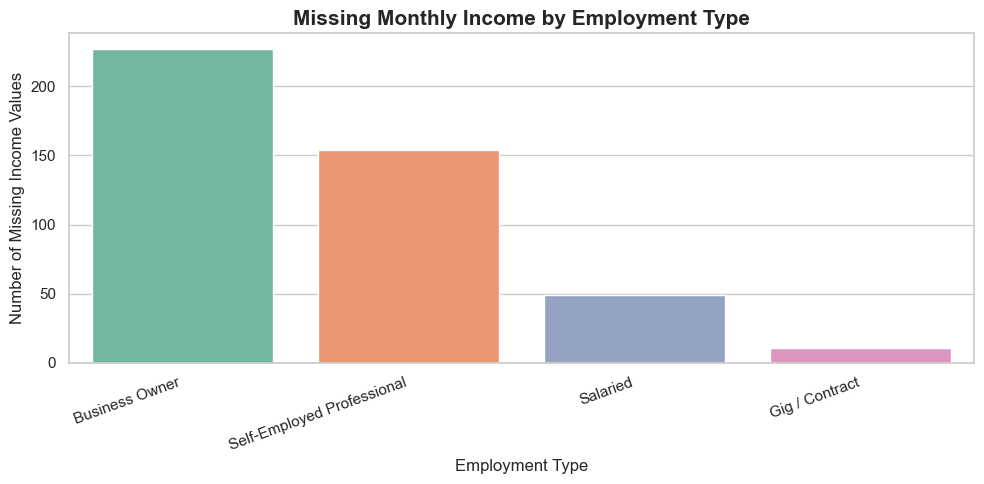

In [8]:

# Count missing monthly income values for each employment type
missing_income_by_job = (
    df[df["monthly_income"].isnull()]
    .groupby("employment_type")
    .size()
    .sort_values(ascending=False)
)

print("Missing monthly income by employment type:")
print(missing_income_by_job)

# Create a colourful bar chart
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    x=missing_income_by_job.index,
    y=missing_income_by_job.values,
    hue=missing_income_by_job.index,
    legend=False,
    palette="Set2"
)

plt.title("Missing Monthly Income by Employment Type",
          fontsize=15, fontweight="bold")
plt.xlabel("Employment Type")
plt.ylabel("Number of Missing Income Values")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


In [9]:

# Calculate the median monthly income for each employment type
median_income_by_job = df.groupby("employment_type")["monthly_income"].median()

print("Median monthly income by employment type:")
print(median_income_by_job.round(2))


Median monthly income by employment type:
employment_type
Business Owner                69500.0
Gig / Contract                28000.0
Salaried                      50000.0
Self-Employed Professional    75000.0
Name: monthly_income, dtype: float64


### Checking Missing Credit Scores

A missing credit score does not always mean that the data is incorrect. Some applicants may not have an established credit history, so they may be new to credit.

I will check the credit history length for applications where the credit score is missing. If their credit history is zero months, this supports the explanation that they have no recorded credit history.

I will keep these applications in the dataset rather than dropping them. The missing credit scores will be handled during the modelling step, and a separate flag will help identify applicants who are new to credit.

In [10]:

# Select applications where the credit score is missing
missing_score_rows = df[df["credit_score"].isnull()]

# Count their credit history values
print("Credit history months for applicants with missing credit scores:")
print(missing_score_rows["credit_history_months"].value_counts().sort_index())

# Count how many have zero months of credit history
zero_history_count = (
    missing_score_rows["credit_history_months"] == 0
).sum()

print("\nMissing credit score applications:", len(missing_score_rows))
print("With zero credit history months:", zero_history_count)


Credit history months for applicants with missing credit scores:
credit_history_months
0    1039
Name: count, dtype: int64

Missing credit score applications: 1039
With zero credit history months: 1039


### Investigating Unusually High Monthly Income

The maximum monthly income is much higher than the typical income in the dataset. Such values may be genuine high incomes, or annual income may have been entered as monthly income by mistake.

I will examine the largest income values and check whether some are exact multiples of 12. This can help identify possible annual-income entry errors, but it does not prove that every such value is incorrect.

I will flag possible errors for review and use a clearly stated correction assumption only for this simulated dataset. In a real bank, these values should be verified against the original application records before being changed.

In [11]:

# Display basic statistics for monthly income
print("Monthly income summary:")
print(df["monthly_income"].describe().round(2))

# Find the maximum monthly income
print("\nMaximum monthly income:", df["monthly_income"].max())

# Display the 15 highest income values
print("\n15 highest monthly income values:")
print(
    df[["application_id", "employment_type", "monthly_income"]]
    .nlargest(15, "monthly_income")
    .to_string(index=False)
)


Monthly income summary:
count      11559.00
mean       60314.86
std        48890.83
min        12000.00
25%        33500.00
50%        50500.00
75%        74750.00
max      1656000.00
Name: monthly_income, dtype: float64

Maximum monthly income: 1656000.0

15 highest monthly income values:
application_id employment_type  monthly_income
     APP101468        Salaried       1656000.0
     APP100301        Salaried       1254000.0
     APP102494        Salaried       1212000.0
     APP100590        Salaried       1068000.0
     APP109850        Salaried        990000.0
     APP101849        Salaried        984000.0
     APP102489        Salaried        972000.0
     APP104011        Salaried        900000.0
     APP104899        Salaried        870000.0
     APP109262        Salaried        702000.0
     APP107427        Salaried        690000.0
     APP108382        Salaried        618000.0
     APP100596        Salaried        546000.0
     APP106910        Salaried        444000.0
    

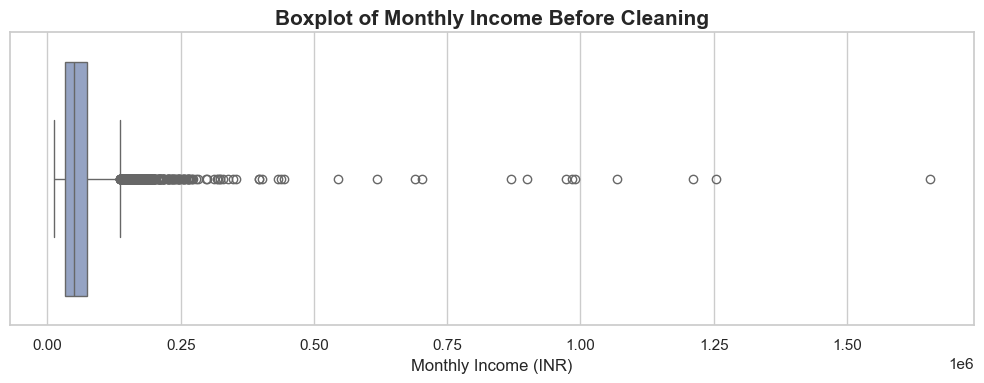

In [12]:

# Draw a boxplot to see the spread of monthly income
plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["monthly_income"],
    color="#8DA0CB"
)

plt.title("Boxplot of Monthly Income Before Cleaning",
          fontsize=15, fontweight="bold")
plt.xlabel("Monthly Income (INR)")
plt.tight_layout()
plt.show()


In [13]:

# Select income values above ₹3,00,000 for closer inspection
high_income = df[df["monthly_income"] > 300000].copy()

# Check which of these values are exact multiples of 12
high_income["multiple_of_12"] = (
    high_income["monthly_income"] % 12 == 0
)

print("Number of income values above ₹3,00,000:",
      len(high_income))

print("Values above ₹3,00,000 that are exact multiples of 12:",
      high_income["multiple_of_12"].sum())

# Display the values for inspection
print("\nIncome values requiring review:")
print(
    high_income[
        ["application_id", "employment_type",
         "monthly_income", "multiple_of_12"]
    ].sort_values("monthly_income", ascending=False).to_string(index=False)
)


Number of income values above ₹3,00,000: 28
Values above ₹3,00,000 that are exact multiples of 12: 25

Income values requiring review:
application_id            employment_type  monthly_income  multiple_of_12
     APP101468                   Salaried       1656000.0            True
     APP100301                   Salaried       1254000.0            True
     APP102494                   Salaried       1212000.0            True
     APP100590                   Salaried       1068000.0            True
     APP109850                   Salaried        990000.0            True
     APP101849                   Salaried        984000.0            True
     APP102489                   Salaried        972000.0            True
     APP104011                   Salaried        900000.0            True
     APP104899                   Salaried        870000.0            True
     APP109262                   Salaried        702000.0            True
     APP107427                   Salaried        69

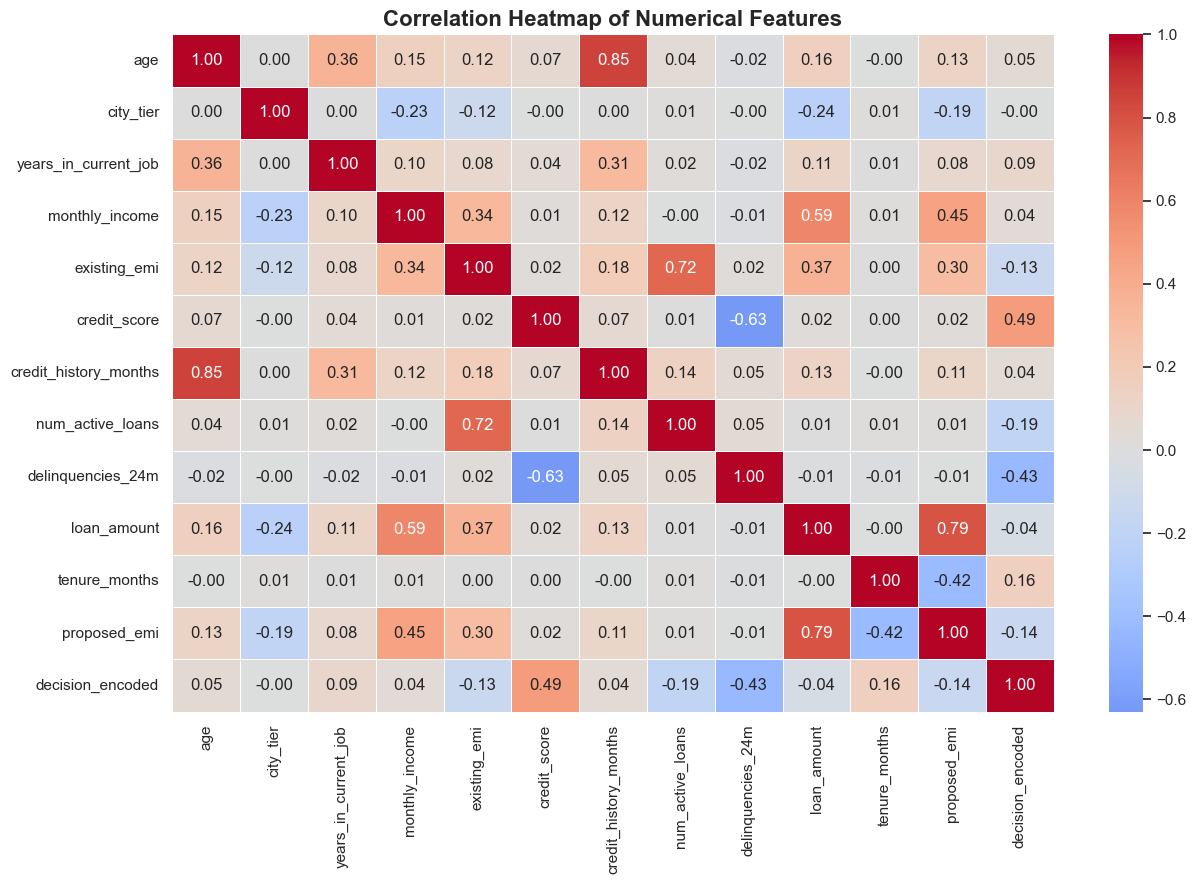

In [14]:

# Make a copy for correlation analysis
corr_df = df.copy()

# Convert the decision column into numbers for this graph only:
# Approved = 1, Declined = 0
corr_df["decision_encoded"] = corr_df["decision"].map({
    "Approved": 1,
    "Declined": 0
})

# Select numerical columns, excluding the identifier
numeric_df = corr_df.select_dtypes(include=np.number).drop(
    columns=["application_id"], errors="ignore"
)

# Calculate correlations between numerical columns
correlation_matrix = numeric_df.corr()

# Plot a colourful heatmap
plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    center=0
)

plt.title("Correlation Heatmap of Numerical Features",
          fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()


In [15]:

# Keep the original dataset unchanged
df_clean = df.copy()

# Step 1: Identify possible annual-income entry errors
# Assumption: income above ₹3,00,000 and exactly divisible by 12
possible_income_errors = (
    df_clean["monthly_income"].gt(300000)
    & np.isclose(df_clean["monthly_income"] % 12, 0)
)

# Count the values that will be adjusted
print("Income values adjusted:", possible_income_errors.sum())

# Step 2: Convert the flagged values to monthly income
df_clean.loc[possible_income_errors, "monthly_income"] = (
    df_clean.loc[possible_income_errors, "monthly_income"] / 12
)

# Step 3: Calculate median income for each employment type
income_medians = df_clean.groupby("employment_type")["monthly_income"].median()

# Step 4: Fill missing income using the relevant employment-type median
df_clean["monthly_income"] = df_clean["monthly_income"].fillna(
    df_clean["employment_type"].map(income_medians)
)

# Step 5: Convert application_date to date format
df_clean["application_date"] = pd.to_datetime(
    df_clean["application_date"], errors="coerce"
)

# Check the results
print("\nMissing monthly income after cleaning:",
      df_clean["monthly_income"].isnull().sum())

print("Missing credit scores retained:",
      df_clean["credit_score"].isnull().sum())

print("\nMonthly income summary after cleaning:")
print(df_clean["monthly_income"].describe().round(2))


Income values adjusted: 25

Missing monthly income after cleaning: 0
Missing credit scores retained: 1039

Monthly income summary after cleaning:
count     12000.00
mean      59307.19
std       35275.13
min       12000.00
25%       34375.00
50%       51500.00
75%       75000.00
max      349000.00
Name: monthly_income, dtype: float64


In [16]:

# Check the cleaned dataset
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values after cleaning:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

# Display a few rows from the cleaned dataset
df_clean.head()


Cleaned dataset shape: (12000, 19)

Missing values after cleaning:
credit_score    1039
dtype: int64


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined


### Data Cleaning Decisions and Reasons

1. **Missing monthly income:** There are 441 missing values. Most are from Business Owners and Self-Employed Professionals. I will fill these values using the median monthly income for the applicant's employment type, because income can vary considerably between applicants.

2. **Missing credit scores:** There are 1,039 missing credit scores, and all these applicants have zero months of credit history. I will keep these rows because they represent applicants with no established credit history. The credit scores will be filled with the median during the modelling step, and a separate flag will identify applicants with no credit score.

3. **Unusually high monthly income:** The maximum monthly income is ₹16,56,000. I found 28 values above ₹3,00,000, of which 25 are exact multiples of 12. This may indicate that annual income was entered as monthly income. For this simulated dataset, I will use a clearly stated assumption to convert values above ₹3,00,000 that are exact multiples of 12 into monthly values by dividing them by 12. In real banking work, these values should be checked against the original records first.

4. **Outliers:** I will use a boxplot to identify unusually high income values. I will not remove values simply because they are outliers; possible data-entry errors will be investigated first.

5. **Correlation heatmap:** I will use a heatmap as an additional exploratory analysis to understand relationships between numerical columns. Correlation alone will not be used to decide whether a value is wrong.

## 5.2 What Drives Approval Today?

### Create credit score bands and calculate approval rates

In [17]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy so the original cleaned dataset is unchanged
df_analysis = df_clean.copy()

# Create the required credit score bands
score_bins = [-float("inf"), 600, 650, 700, 750, 800, float("inf")]

score_labels = [
    "Below 600",
    "600–649",
    "650–699",
    "700–749",
    "750–799",
    "800+"
]

df_analysis["credit_score_band"] = pd.cut(
    df_analysis["credit_score"],
    bins=score_bins,
    labels=score_labels,
    right=False
)

# Give applicants with no credit score a separate category
df_analysis["credit_score_band"] = (
    df_analysis["credit_score_band"]
    .cat.add_categories(["No score"])
    .fillna("No score")
)

# Calculate approval rate for each credit score band
df_analysis["is_approved"] = (
    df_analysis["decision"].str.strip().str.lower() == "approved"
).astype(int)

score_approval = (
    df_analysis.groupby("credit_score_band", observed=False)["is_approved"]
    .mean()
    .mul(100)
    .reindex(score_labels + ["No score"])
    .reset_index(name="Approval Rate (%)")
)

print("Approval rate by credit score band:")
display(score_approval.round(2))


Approval rate by credit score band:


,credit_score_band,Approval Rate (%)
0,Below 600,2.03
1,600–649,3.22
2,650–699,32.50
3,700–749,54.37
4,750–799,77.20
5,800+,85.19
6,No score,53.90


This table shows the percentage of applications approved in each credit score group. For example, an approval rate of 70% means 70 out of every 100 applications in that group were approved historically.

### Plot approval rate by credit score band

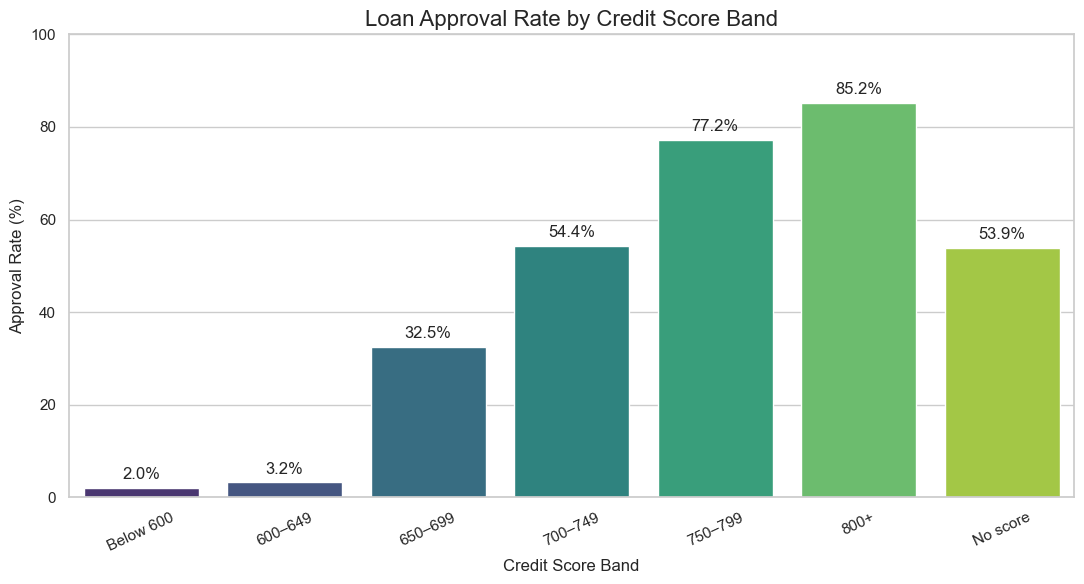

In [18]:

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=score_approval,
    x="credit_score_band",
    y="Approval Rate (%)",
    hue="credit_score_band",
    palette="viridis",
    legend=False
)

plt.title("Loan Approval Rate by Credit Score Band", fontsize=16)
plt.xlabel("Credit Score Band", fontsize=12)
plt.ylabel("Approval Rate (%)", fontsize=12)
plt.ylim(0, 100)
plt.xticks(rotation=25)

# Display approval percentages above the bars
for bar in ax.patches:
    height = bar.get_height()
    if pd.notna(height):
        ax.annotate(
            f"{height:.1f}%",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points"
        )

plt.tight_layout()
plt.show()


### Calculate and plot approval rate by employment type

Approval rate by employment type:


,employment_type,Approval Rate (%)
0,Salaried,58.37
1,Business Owner,51.17
2,Self-Employed Professional,50.56
3,Gig / Contract,34.94


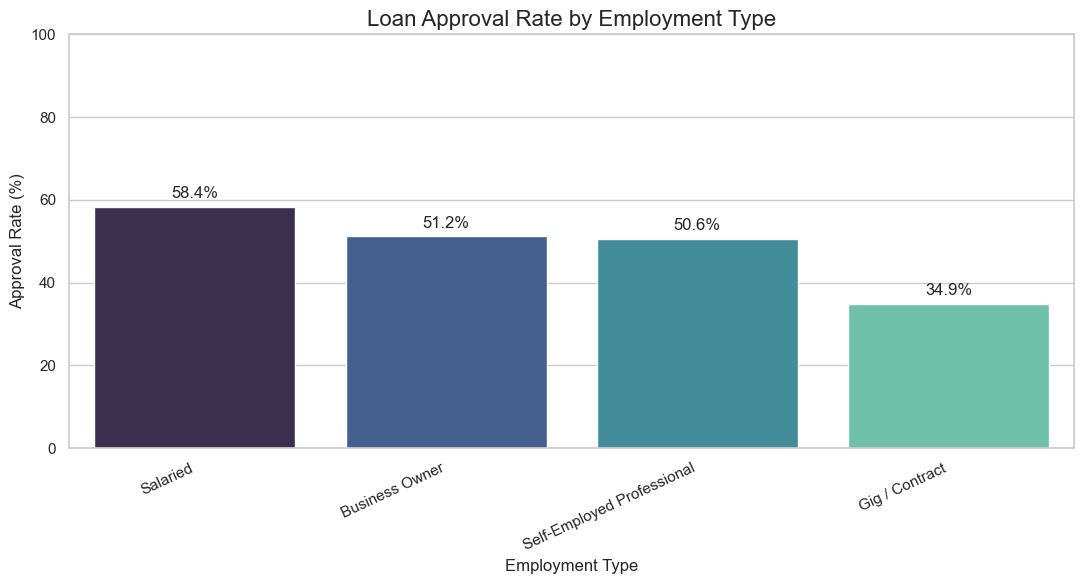

In [19]:

# Calculate approval rate for each employment type
employment_approval = (
    df_analysis.groupby("employment_type", dropna=False)["is_approved"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index(name="Approval Rate (%)")
)

print("Approval rate by employment type:")
display(employment_approval.round(2))

# Plot approval rates
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=employment_approval,
    x="employment_type",
    y="Approval Rate (%)",
    hue="employment_type",
    palette="mako",
    legend=False
)

plt.title("Loan Approval Rate by Employment Type", fontsize=16)
plt.xlabel("Employment Type", fontsize=12)
plt.ylabel("Approval Rate (%)", fontsize=12)
plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")

# Show percentages above the bars
for bar in ax.patches:
    height = bar.get_height()
    if pd.notna(height):
        ax.annotate(
            f"{height:.1f}%",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points"
        )

plt.tight_layout()
plt.show()


### Findings: What Drives Approval Today?

**1. Is there a credit score below which applications are almost never approved?**

Yes. Applicants with credit scores below 600 have an approval rate of only **2.0%**, while applicants with scores between 600 and 649 have an approval rate of **3.2%**. This shows that applications with credit scores below 650 are rarely approved.

This suggests that the bank follows an unwritten credit policy that strongly favours applicants with higher credit scores. A low credit score appears to be a major factor associated with loan rejection.

**2. How do applicants with no credit score fare compared to scored applicants?**

Applicants with no credit score have an approval rate of **53.9%**. This is much higher than the approval rates for applicants with scores below 650. Their approval rate is also higher than that of applicants in the 650–699 band, which is 32.5%.

This suggests that the bank does not automatically reject applicants who have no credit score. Other factors may influence their approval decisions. Therefore, missing credit scores should not automatically be treated as evidence of poor creditworthiness.

**3. How does employment type affect approval?**

Salaried applicants have the highest approval rate at **58.4%**, followed by Business Owners at **51.2%** and Self-Employed Professionals at **50.6%**. Gig/Contract workers have the lowest approval rate at **34.9%**.

This suggests that the bank's historical decisions are associated with employment type. Salaried applicants may have more predictable income, while Gig/Contract workers may have less predictable income. However, this graph alone does not prove why these differences exist.

**Conclusion**

Credit score and employment type are important factors to investigate when understanding the bank's historical approval decisions. The very low approval rates below a credit score of 650 suggest a strong historical rejection pattern, while the approval rate for applicants with no score shows that missing credit history does not automatically lead to rejection. These findings will guide the next steps in building the credit pre-screening model.

## 5.3 Engineer the Affordability Features

#### Create the three new columns

In [20]:

# Create a copy of the cleaned dataset
df_features = df_clean.copy()

# 1. FOIR: share of monthly income committed to loan EMIs
df_features["foir"] = (
    (df_features["existing_emi"] + df_features["proposed_emi"])
    / df_features["monthly_income"]
)

# 2. Loan-to-income: loan amount compared with annual income
df_features["loan_to_income"] = (
    df_features["loan_amount"]
    / (df_features["monthly_income"] * 12)
)

# 3. New-to-credit flag:
# 1 means credit score is missing; 0 means credit score is available
df_features["is_ntc"] = df_features["credit_score"].isnull().astype(int)

# Display the new features
display(
    df_features[
        ["monthly_income", "existing_emi", "proposed_emi",
         "foir", "loan_to_income", "credit_score", "is_ntc"]
    ].head()
)


,monthly_income,existing_emi,proposed_emi,foir,loan_to_income,credit_score,is_ntc
0,95000.0,23500.0,6600.0,0.316842,0.210526,784.0,0
1,43000.0,8500.0,5000.0,0.313953,0.281008,790.0,0
2,35000.0,3500.0,11800.0,0.437143,0.821429,718.0,0
3,44500.0,0.0,4600.0,0.103371,0.252809,NaN,1
4,83500.0,6000.0,33600.0,0.474251,0.698603,700.0,0


foir = 0.35 means 35% of monthly income goes toward the existing and proposed EMIs.



loan_to_income = 0.50 means the requested loan equals 50% of annual income.



is_ntc = 1 means the applicant has no recorded credit score.

#### Group FOIR into five bands

In [21]:

# Define FOIR bands as proportions
foir_bins = [-float("inf"), 0.30, 0.40, 0.50, 0.55, float("inf")]

foir_labels = [
    "Below 30%",
    "30–40%",
    "40–50%",
    "50–55%",
    "Above 55%"
]

# Assign each application to a FOIR band
df_features["foir_band"] = pd.cut(
    df_features["foir"],
    bins=foir_bins,
    labels=foir_labels,
    right=False
)

# Calculate approval rate for each FOIR band
df_features["is_approved"] = (
    df_features["decision"].str.strip().str.lower() == "approved"
).astype(int)

foir_approval = (
    df_features.groupby("foir_band", observed=False)["is_approved"]
    .mean()
    .mul(100)
    .reindex(foir_labels)
    .reset_index(name="Approval Rate (%)")
)

print("Approval rate by FOIR band:")
display(foir_approval.round(2))


Approval rate by FOIR band:


,foir_band,Approval Rate (%)
0,Below 30%,65.48
1,30–40%,58.98
2,40–50%,47.79
3,50–55%,32.39
4,Above 55%,15.77


#### Plot the approval rate by FOIR band

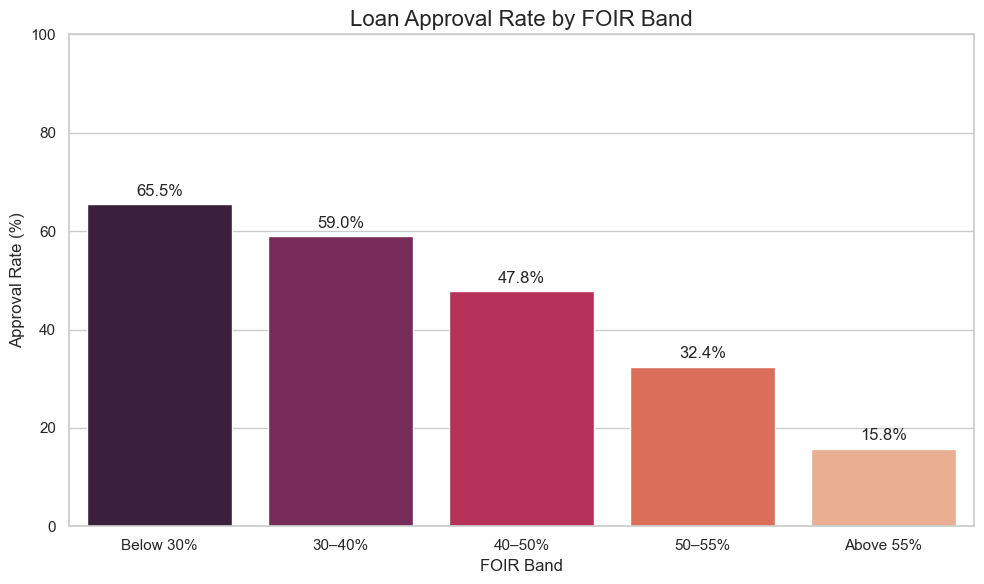

In [22]:

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=foir_approval,
    x="foir_band",
    y="Approval Rate (%)",
    hue="foir_band",
    palette="rocket",
    legend=False
)

plt.title("Loan Approval Rate by FOIR Band", fontsize=16)
plt.xlabel("FOIR Band", fontsize=12)
plt.ylabel("Approval Rate (%)", fontsize=12)
plt.ylim(0, 100)

# Add approval percentages above the bars
for bar in ax.patches:
    height = bar.get_height()
    if pd.notna(height):
        ax.annotate(
            f"{height:.1f}%",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            xytext=(0, 4),
            textcoords="offset points"
        )

plt.tight_layout()
plt.show()


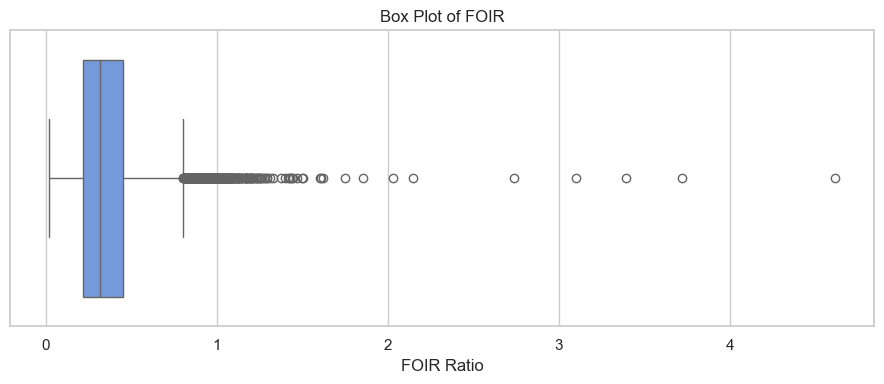

In [23]:

# Check the distribution and outliers in FOIR
plt.figure(figsize=(9, 4))

sns.boxplot(
    x=df_features["foir"],
    color="cornflowerblue"
)

plt.title("Box Plot of FOIR")
plt.xlabel("FOIR Ratio")
plt.tight_layout()
plt.show()


### FOIR Distribution and Outlier Analysis

The box plot helps identify unusually high or low FOIR values. These outliers may indicate high repayment commitments or possible data errors and should be investigated before taking any action.

### Findings: FOIR and Loan Approval

**1. At what FOIR level do approvals fall sharply?**

The approval rate decreases as FOIR increases. Applicants with FOIR below 30% have the highest approval rate at 65.5%. This falls to 59.0% for the 30–40% band, 47.8% for the 40–50% band, 32.4% for the 50–55% band, and just 15.8% for applicants above 55%.

The decline becomes particularly noticeable above 50% FOIR. This suggests that applicants with a larger share of their income committed to EMIs are less likely to be approved under the bank's historical policy.

**2. What FOIR limit would you propose for the credit policy?**

I would propose **50% FOIR as an initial limit for standard approval consideration**. Applications with FOIR below 50% could be considered for approval if they meet the other credit policy requirements.

Applications with FOIR between 50% and 55% should receive additional checks or manual review. Applications above 55% should receive stricter affordability checks and manual review rather than being automatically rejected based on FOIR alone.

**Conclusion**

FOIR is a useful measure of an applicant's repayment commitments. The historical approval rate falls to 32.4% in the 50–55% band and 15.8% above 55%. Therefore, a 50% limit is a reasonable starting point for further policy testing. The final limit should also be checked against repayment outcomes, applicant risk, and the bank's affordability requirements.

## 5.4 Build the Logistic Regression Pre-Screener


The target will be 1 = Declined and 0 = Approved. We’ll fill missing credit scores with the median, encode categorical features, scale numerical features, split the data into training and testing sets, and evaluate the model.

### Prepare the target and selected features

In [24]:

# Import the required libraries
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Create the target: 1 = Declined, 0 = Approved
y = (
    df_features["decision"]
    .str.strip()
    .str.lower()
    .map({"declined": 1, "approved": 0})
)

# Select only the features allowed by the assignment
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months"
]

categorical_features = [
    "city_tier",
    "employment_type",
    "loan_purpose"
]

feature_columns = numeric_features + categorical_features

X = df_features[feature_columns].copy()

# Remove rows only if the target decision itself is missing or invalid
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("Feature dataset shape:", X.shape)
print("\nTarget distribution:")
print(y.value_counts().rename(index={0: "Approved", 1: "Declined"}))


Feature dataset shape: (12000, 12)

Target distribution:
decision
Approved    6353
Declined    5647
Name: count, dtype: int64


### Split the data into training and testing sets

In [25]:

# Split data: 80% for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])


Training rows: 9600
Testing rows: 2400


stratify=y keeps the proportion of approved and declined applications similar in both sets. We fit preprocessing steps on the training data only to avoid information leakage from the test set.

### Fill missing values, encode categories, and scale numerical features

In [26]:

# Process numerical features:
# Fill missing values with the median and scale the values
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical features:
# Fill missing categories with the most common value and encode them
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Build the complete Logistic Regression pipeline
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Train the model
logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


### Evaluate the model

In [27]:

# Predict the decisions for the test dataset
y_pred = logistic_model.predict(X_test)

print("Predictions created successfully!")
print("Number of predictions:", len(y_pred))


Predictions created successfully!
Number of predictions: 2400


In [28]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Calculate overall accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate ROC-AUC using the probability of Declined (class 1)
y_prob = logistic_model.predict_proba(X_test)[:, 1]
roc_auc = roc_auc_score(y_test, y_prob)

# Calculate metrics for both classes
metrics = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score"],
    "Approved (%)": [
        precision_score(y_test, y_pred, pos_label=0, zero_division=0) * 100,
        recall_score(y_test, y_pred, pos_label=0, zero_division=0) * 100,
        f1_score(y_test, y_pred, pos_label=0, zero_division=0) * 100
    ],
    "Declined (%)": [
        precision_score(y_test, y_pred, pos_label=1, zero_division=0) * 100,
        recall_score(y_test, y_pred, pos_label=1, zero_division=0) * 100,
        f1_score(y_test, y_pred, pos_label=1, zero_division=0) * 100
    ]
})

# Display accuracy and ROC-AUC
print(f"Overall Accuracy: {accuracy * 100:.2f}%")
print(f"ROC-AUC Score: {roc_auc:.4f} ({roc_auc * 100:.2f}%)")

# Display classification metrics
print("\nClassification Metrics:")
display(metrics.round(2))


Overall Accuracy: 78.54%
ROC-AUC Score: 0.8671 (86.71%)

Classification Metrics:


,Metric,Approved (%),Declined (%)
0,Precision,78.51,78.58
1,Recall,81.90,74.76
2,F1-Score,80.17,76.62


### Confusion Matrix

Confusion Matrix:


,Predicted Approved,Predicted Declined
Actual Approved,1041,230
Actual Declined,285,844


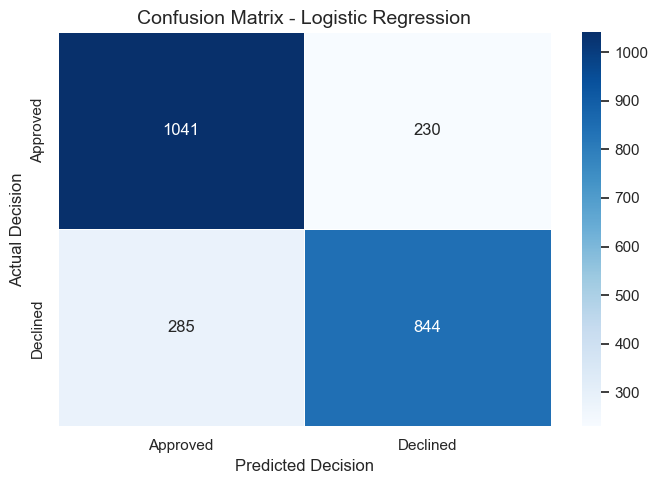

False Declines (Approved predicted as Declined): 230


In [29]:

from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create confusion matrix: 0 = Approved, 1 = Declined
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

# Display the confusion matrix as a table
cm_table = pd.DataFrame(
    cm,
    index=["Actual Approved", "Actual Declined"],
    columns=["Predicted Approved", "Predicted Declined"]
)

print("Confusion Matrix:")
display(cm_table)

# Plot the confusion matrix
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Approved", "Declined"],
    yticklabels=["Approved", "Declined"],
    linewidths=0.5
)

plt.title("Confusion Matrix - Logistic Regression", fontsize=14)
plt.xlabel("Predicted Decision")
plt.ylabel("Actual Decision")
plt.tight_layout()
plt.show()

# Count historically approved applicants wrongly predicted as declined
print(
    "False Declines (Approved predicted as Declined):",
    cm[0, 1]
)


### Find the five features with the largest coefficients

In [30]:

# Get the names of all processed features
feature_names = (
    logistic_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Logistic Regression coefficients
coefficients = logistic_model.named_steps["model"].coef_[0]

# Create a table of features and their coefficients
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Show the five largest positive coefficients
# Positive coefficients push predictions towards Declined
top_five = coefficient_table.sort_values(
    by="Coefficient",
    ascending=False
).head(5)

print("Top 5 features pushing predictions towards Declined:")
display(top_five.round(4))


Top 5 features pushing predictions towards Declined:


,Feature,Coefficient
2,numeric__foir,1.2464
4,numeric__delinquencies_24m,0.9759
13,categorical__employment_type_Gig / Contract,0.6120
17,categorical__loan_purpose_Debt Consolidation,0.3891
1,numeric__is_ntc,0.3797


In [31]:

# Get the names of all processed features
feature_names = (
    logistic_model.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get Logistic Regression coefficients
coefficients = logistic_model.named_steps["model"].coef_[0]

# Create a table of features and their coefficients
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Select the 5 largest positive coefficients
top_positive = coefficient_table.nlargest(
    5, "Coefficient"
)

# Select the 5 largest negative coefficients
top_negative = coefficient_table.nsmallest(
    5, "Coefficient"
)

# Combine positive and negative coefficients
top_coefficients = pd.concat(
    [top_negative, top_positive]
)

# Add direction labels for the graph
top_coefficients["Direction"] = top_coefficients["Coefficient"].apply(
    lambda x: "Pushes toward Approved" if x < 0
    else "Pushes toward Declined"
)

# Sort coefficients for displaying the graph
top_coefficients = top_coefficients.sort_values(
    by="Coefficient",
    ascending=True
)

# Display the combined coefficient table
print("Largest Positive and Negative Logistic Regression Coefficients:")
display(top_coefficients.round(4))


Largest Positive and Negative Logistic Regression Coefficients:


,Feature,Coefficient,Direction
0,numeric__credit_score,-0.9951,Pushes toward Approved
14,categorical__employment_type_Salaried,-0.4463,Pushes toward Approved
3,numeric__loan_to_income,-0.2980,Pushes toward Approved
16,categorical__loan_purpose_Consumer Durables,-0.1751,Pushes toward Approved
6,numeric__years_in_current_job,-0.1416,Pushes toward Approved
1,numeric__is_ntc,0.3797,Pushes toward Declined
17,categorical__loan_purpose_Debt Consolidation,0.3891,Pushes toward Declined
13,categorical__employment_type_Gig / Contract,0.6120,Pushes toward Declined
4,numeric__delinquencies_24m,0.9759,Pushes toward Declined
2,numeric__foir,1.2464,Pushes toward Declined


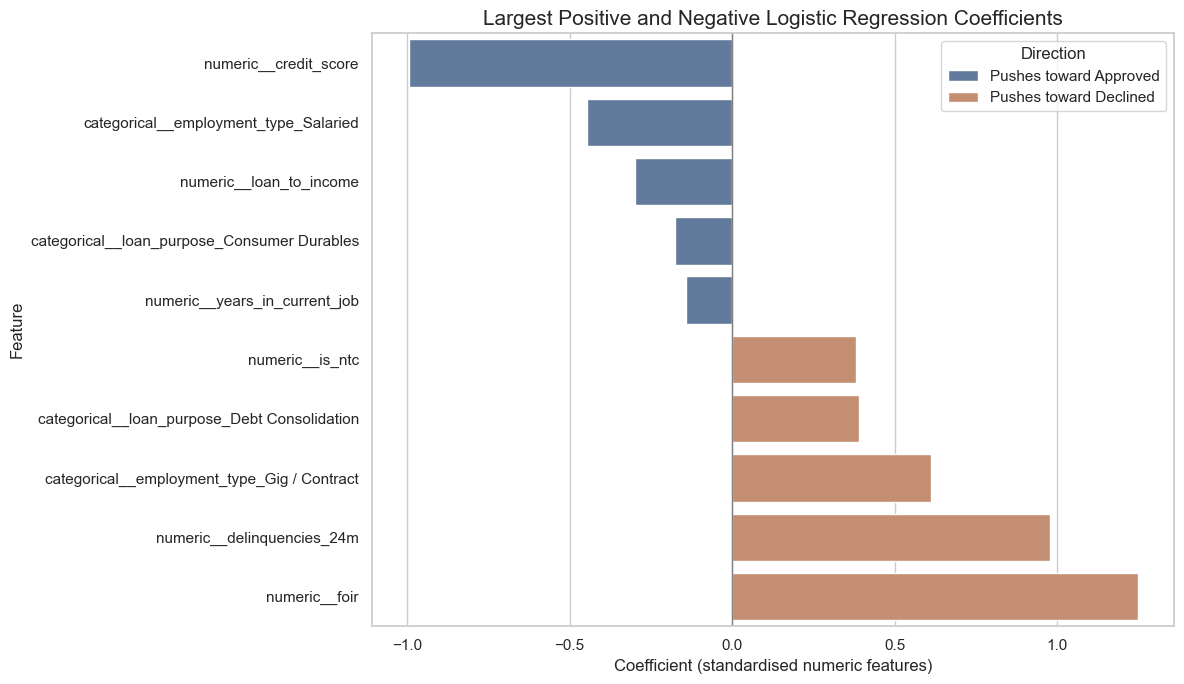

In [32]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Select the 5 largest positive coefficients
top_positive = coefficient_table.nlargest(5, "Coefficient")

# Select the 5 largest negative coefficients
top_negative = coefficient_table.nsmallest(5, "Coefficient")

# Combine both groups
top_coefficients = pd.concat([top_negative, top_positive]).copy()

# Add a label to show the direction of each coefficient
top_coefficients["Direction"] = top_coefficients["Coefficient"].apply(
    lambda x: "Pushes toward Approved" if x < 0
    else "Pushes toward Declined"
)

# Sort coefficients for a horizontal bar graph
top_coefficients = top_coefficients.sort_values(
    by="Coefficient",
    ascending=True
)

# Create the graph
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_coefficients,
    x="Coefficient",
    y="Feature",
    hue="Direction",
    palette={
        "Pushes toward Approved": "#5878A5",
        "Pushes toward Declined": "#D18A63"
    },
    dodge=False
)

# Add title and axis labels
plt.title(
    "Largest Positive and Negative Logistic Regression Coefficients",
    fontsize=15
)
plt.xlabel("Coefficient (standardised numeric features)", fontsize=12)
plt.ylabel("Feature", fontsize=12)

# Add a zero reference line
plt.axvline(x=0, color="gray", linewidth=1)

# Display legend and adjust layout
plt.legend(title="Direction")
plt.tight_layout()
plt.show()


The bar graph shows the five largest positive and five largest negative coefficients from the Logistic Regression model.

- **Positive coefficients (orange bars):** FOIR, delinquencies in the last 24 months, gig/contract employment, debt consolidation loan purpose, and the `is_ntc` flag are associated with predictions towards Declined.
- **Negative coefficients (blue bars):** Credit score, salaried employment, loan-to-income ratio, consumer durables loan purpose, and years in the current job are associated with predictions towards Approved.

Among the displayed features, FOIR and delinquencies in the last 24 months have the largest positive coefficients, indicating a stronger association with predicted declines. Credit score has the largest negative coefficient, indicating an association with predictions away from Declined.

These coefficients show relationships learned from historical loan decisions; they do not prove that any feature directly causes approval or rejection. The credit team should review these patterns alongside the bank's credit policy before using the model to support screening decisions.

### Logistic Regression Model Evaluation

**1. Model Performance**

The Logistic Regression model achieved an accuracy of **78.54%** on the test dataset. Accuracy measures the overall percentage of correct predictions. Precision, recall, and F1-score help us understand how well the model identifies historically Approved and Declined applications.

**2. Confusion Matrix in Business Language**

The model wrongly predicted **230 historically approved applications as Declined**. These are false declines and represent applicants who were approved under the historical policy but could be incorrectly rejected by the model.

The model also predicted **285 historically declined applications as Approved**. These are missed declines and represent applications that the model failed to identify as historically declined. Such cases could allow potentially risky applications to pass through the initial screening process.

The model correctly predicted **1,041 Approved applications** and **844 Declined applications**. These results show why accuracy alone is not enough to evaluate the model. We must consider both the risk of wrongly rejecting good applicants and the risk of allowing potentially risky applications to pass screening.

**3. Top Five Logistic Regression Coefficients**

The five largest positive coefficients identify features most strongly associated with predictions towards Declined. Negative coefficients indicate features associated with predictions towards Approved, relative to the model's reference categories and other features.

These results help the credit team understand which factors influence the model's predictions. However, coefficients show associations with historical decisions and do not prove that a feature causes rejection. The findings should be reviewed alongside the bank's credit policy.

**Conclusion**

The Logistic Regression model provides a baseline for predicting historical loan decisions. Before using it for credit pre-screening, we must carefully review false declines, missed declines, and the factors influencing its predictions.

The model should support careful application screening rather than automatically reject applicants based only on its predictions. Further evaluation at different prediction thresholds and appropriate human review are necessary before using it to support lending decisions.

## 5.5 Set the Auto-Decline Threshold

### Compare all seven thresholds

In [33]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Thresholds required by the assignment
thresholds = [0.5, 0.6, 0.7, 0.8, 0.85, 0.9, 0.95]

# Get the probability that each application will be Declined (class 1)
decline_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Store the actual historical decisions
actual_decisions = np.asarray(y_test)

results = []

for threshold in thresholds:

    # Applications whose decline probability meets the threshold
    auto_decline = decline_probabilities >= threshold

    # Count applications selected for auto-decline
    total_auto_declined = auto_decline.sum()

    # Among them, count applications historically Approved
    wrongly_declined = np.sum(
        auto_decline & (actual_decisions == 0)
    )

    # Percentage of all test applications auto-declined
    auto_decline_pct = (
        total_auto_declined / len(actual_decisions) * 100
    )

    # Percentage of auto-declined applications that were Approved
    wrong_decline_pct = (
        wrongly_declined / total_auto_declined * 100
        if total_auto_declined > 0
        else np.nan
    )

    results.append({
        "Threshold": threshold,
        "Auto-Declined Applications": total_auto_declined,
        "Auto-Declined (%)": auto_decline_pct,
        "Wrongly Declined (%)": wrong_decline_pct
    })

# Create and display the results table
threshold_table = pd.DataFrame(results)

print("Auto-Decline Threshold Comparison")
display(threshold_table.round(2))


Auto-Decline Threshold Comparison


,Threshold,Auto-Declined Applications,Auto-Declined (%),Wrongly Declined (%)
0,0.50,1074,44.75,21.42
1,0.60,892,37.17,16.70
2,0.70,736,30.67,11.68
3,0.80,568,23.67,7.39
4,0.85,459,19.12,5.66
5,0.90,351,14.62,4.27
6,0.95,232,9.67,2.16


### Plot both lines on one chart

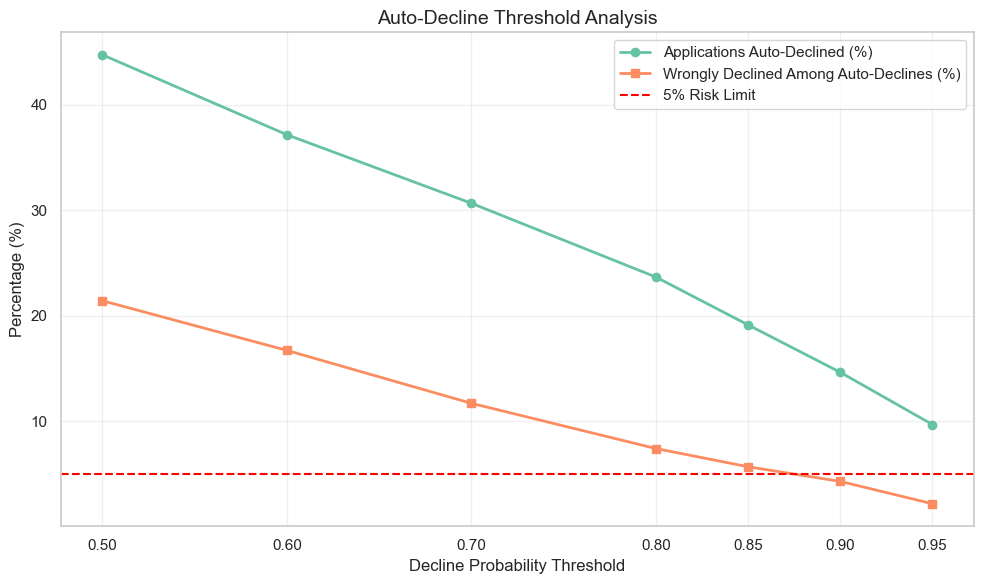

In [34]:

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_table["Threshold"],
    threshold_table["Auto-Declined (%)"],
    marker="o",
    linewidth=2,
    label="Applications Auto-Declined (%)"
)

plt.plot(
    threshold_table["Threshold"],
    threshold_table["Wrongly Declined (%)"],
    marker="s",
    linewidth=2,
    label="Wrongly Declined Among Auto-Declines (%)"
)

# Bank's maximum acceptable wrongly declined rate
plt.axhline(
    y=5,
    color="red",
    linestyle="--",
    label="5% Risk Limit"
)

plt.title("Auto-Decline Threshold Analysis", fontsize=14)
plt.xlabel("Decline Probability Threshold")
plt.ylabel("Percentage (%)")
plt.xticks(thresholds)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


### Select the threshold that meets the bank's rule

In [35]:

# Keep thresholds where wrongly declined applications are at most 5%
eligible_thresholds = threshold_table[
    threshold_table["Wrongly Declined (%)"] <= 5
]

if eligible_thresholds.empty:
    print("No tested threshold meets the bank's 5% risk limit.")
    print("Do not select a threshold until the policy is reviewed.")
else:
    # Choose the eligible threshold that auto-declines the most applications
    best_row = eligible_thresholds.loc[
        eligible_thresholds["Auto-Declined Applications"].idxmax()
    ]

    # Monthly business case
    monthly_applications = 3000
    minutes_per_review = 25

    monthly_auto_declined = (
        monthly_applications * best_row["Auto-Declined (%)"] / 100
    )

    analyst_hours_saved = (
        monthly_auto_declined * minutes_per_review / 60
    )

    print(f"Selected threshold: {best_row['Threshold']:.2f}")
    print(
        f"Wrongly declined rate: "
        f"{best_row['Wrongly Declined (%)']:.2f}%"
    )
    print(
        f"Test applications auto-declined: "
        f"{int(best_row['Auto-Declined Applications'])}"
    )
    print(
        f"Percentage auto-declined: "
        f"{best_row['Auto-Declined (%)']:.2f}%"
    )
    print(
        f"Estimated applications freed per month: "
        f"{monthly_auto_declined:.0f}"
    )
    print(
        f"Estimated analyst hours freed per month: "
        f"{analyst_hours_saved:.1f}"
    )


Selected threshold: 0.90
Wrongly declined rate: 4.27%
Test applications auto-declined: 351
Percentage auto-declined: 14.62%
Estimated applications freed per month: 439
Estimated analyst hours freed per month: 182.8


### Auto-Decline Threshold Selection — Business Interpretation

**1. Selected Threshold**

The selected auto-decline threshold is **0.90 (90%)**. At this threshold, only applications with a predicted probability of Declined of at least 90% are considered for automatic decline.

**2. Risk Limit**

The percentage of historically Approved applicants among auto-declined applications is **4.27%**, which meets the bank's requirement of no more than 5%. Therefore, the selected threshold satisfies the specified risk limit on the test dataset.

**3. Monthly Business Impact**

With 3,000 applications per month, approximately **439 applications** could be auto-declined, freeing an estimated **182.8 analyst hours per month**, assuming each application would otherwise require 25 minutes of manual review.

**Conclusion**

A threshold of 0.90 provides a balance between reducing manual workload and limiting the risk of wrongly declining historically Approved applicants. Before implementation, the bank should validate this threshold on additional data and confirm that its automatic-decline policy is appropriate.

## 5.6 Fairness Check

### Historical approval rate by gender

Historical Approval Rate by Gender


,gender,Approval Rate (%)
0,Female,50.43
1,Male,54.10


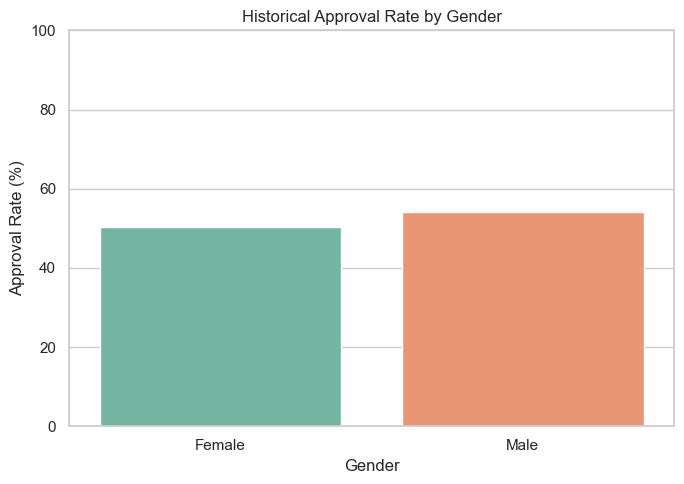

Historical Approval Rate by Employment Type and Gender


,employment_type,gender,Approval Rate (%)
0,Business Owner,Female,51.62
1,Business Owner,Male,51.05
2,Gig / Contract,Female,34.65
3,Gig / Contract,Male,35.18
4,Salaried,Female,56.79
5,Salaried,Male,59.06
6,Self-Employed Professional,Female,47.63
7,Self-Employed Professional,Male,51.97


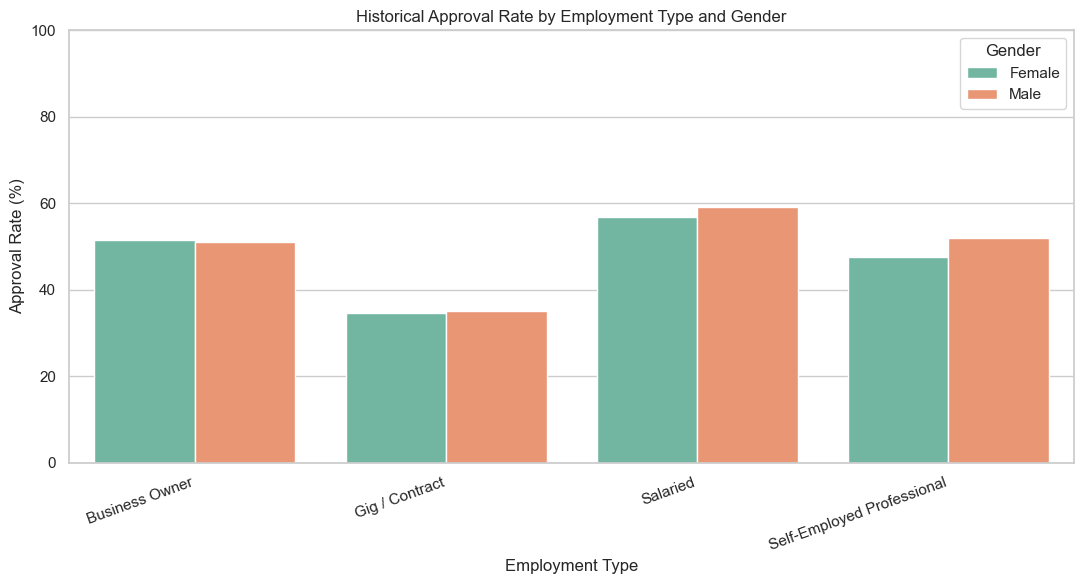

In [36]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Work with the cleaned dataset
fairness_df = df_clean.copy()

# Standardise decision labels
fairness_df["decision_clean"] = (
    fairness_df["decision"].astype("string").str.strip().str.lower()
)

# Mark historically approved applications
fairness_df["is_approved"] = (
    fairness_df["decision_clean"] == "approved"
).astype(int)

# Historical approval rate by gender
approval_by_gender = (
    fairness_df.groupby("gender", dropna=False)["is_approved"]
    .mean().mul(100).reset_index(name="Approval Rate (%)")
)

print("Historical Approval Rate by Gender")
display(approval_by_gender.round(2))

# Graph 1: Overall historical approval rate by gender
plt.figure(figsize=(7, 5))
sns.barplot(
    data=approval_by_gender,
    x="gender",
    y="Approval Rate (%)",
    hue="gender",
    palette="Set2",
    legend=False
)
plt.title("Historical Approval Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

# Approval rate within each employment type
approval_by_employment = (
    fairness_df.groupby(
        ["employment_type", "gender"], dropna=False
    )["is_approved"]
    .mean().mul(100).reset_index(name="Approval Rate (%)")
)

print("Historical Approval Rate by Employment Type and Gender")
display(approval_by_employment.round(2))

# Graph 2: Approval rate by employment type and gender
plt.figure(figsize=(11, 6))
sns.barplot(
    data=approval_by_employment,
    x="employment_type",
    y="Approval Rate (%)",
    hue="gender",
    palette="Set2"
)
plt.title("Historical Approval Rate by Employment Type and Gender")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.legend(title="Gender")
plt.tight_layout()
plt.show()


### Median monthly income and Gig / Contract share by gender

Median Monthly Income by Gender


,gender,Median Monthly Income
0,Female,45000.0
1,Male,55000.0


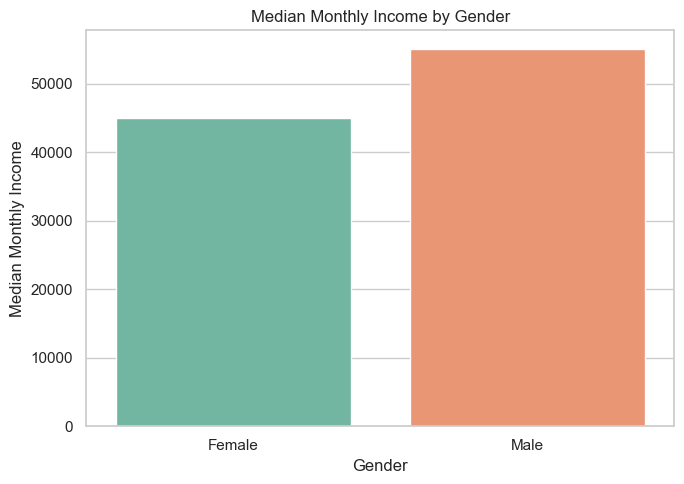

Gig / Contract Share by Gender


,gender,Gig / Contract Share (%)
0,Female,21.37
1,Male,11.64


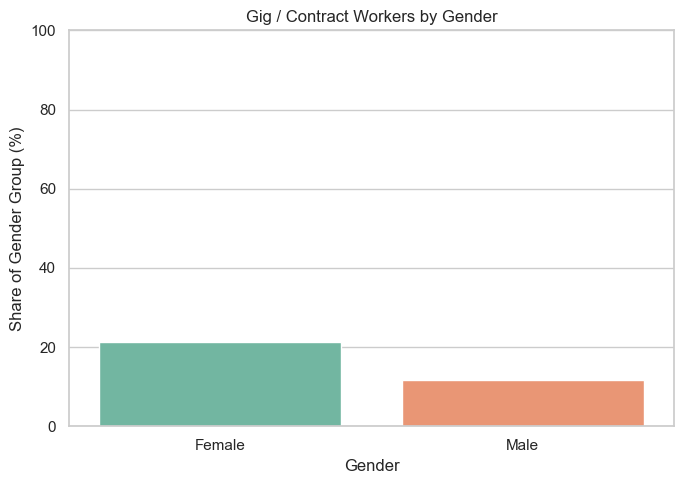

In [37]:

# Calculate median monthly income by gender
median_income = (
    fairness_df.groupby("gender", dropna=False)["monthly_income"]
    .median().reset_index(name="Median Monthly Income")
)

print("Median Monthly Income by Gender")
display(median_income.round(2))

# Graph 3: Median monthly income by gender
plt.figure(figsize=(7, 5))
sns.barplot(
    data=median_income,
    x="gender",
    y="Median Monthly Income",
    hue="gender",
    palette="Set2",
    legend=False
)
plt.title("Median Monthly Income by Gender")
plt.xlabel("Gender")
plt.ylabel("Median Monthly Income")
plt.tight_layout()
plt.show()

# Calculate the share of Gig / Contract workers within each gender
fairness_df["is_gig_contract"] = (
    fairness_df["employment_type"].astype("string").str.strip()
    == "Gig / Contract"
).astype(int)

gig_share = (
    fairness_df.groupby("gender", dropna=False)["is_gig_contract"]
    .mean().mul(100).reset_index(name="Gig / Contract Share (%)")
)

print("Gig / Contract Share by Gender")
display(gig_share.round(2))

# Graph 4: Gig / Contract share by gender
plt.figure(figsize=(7, 5))
sns.barplot(
    data=gig_share,
    x="gender",
    y="Gig / Contract Share (%)",
    hue="gender",
    palette="Set2",
    legend=False
)
plt.title("Gig / Contract Workers by Gender")
plt.xlabel("Gender")
plt.ylabel("Share of Gender Group (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Auto-decline rate by gender at threshold 0.90

Auto-Decline Rate by Gender at Threshold 0.90


,gender,Auto-Decline Rate (%)
0,Female,15.33
1,Male,14.30


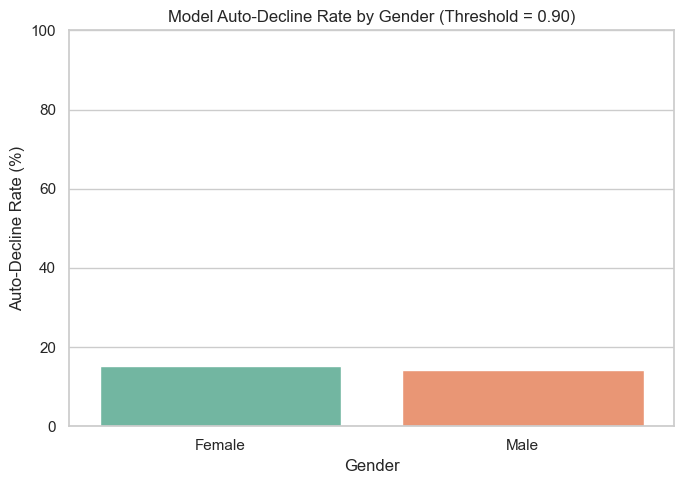

In [38]:

# Use the selected threshold from Step 5.5
selected_threshold = 0.90

# Get decline probabilities for the test dataset
decline_probabilities = logistic_model.predict_proba(X_test)[:, 1]

# Keep gender aligned with the test applications by their row index
test_fairness = pd.DataFrame(index=X_test.index)
test_fairness["gender"] = df_features.loc[X_test.index, "gender"]
test_fairness["decline_probability"] = decline_probabilities

# Flag applications meeting the auto-decline threshold
test_fairness["auto_declined"] = (
    test_fairness["decline_probability"] >= selected_threshold
).astype(int)

# Calculate auto-decline rate by gender
auto_decline_by_gender = (
    test_fairness.groupby("gender", dropna=False)["auto_declined"]
    .mean().mul(100).reset_index(name="Auto-Decline Rate (%)")
)

print("Auto-Decline Rate by Gender at Threshold 0.90")
display(auto_decline_by_gender.round(2))

# Graph 5: Auto-decline rate by gender
plt.figure(figsize=(7, 5))
sns.barplot(
    data=auto_decline_by_gender,
    x="gender",
    y="Auto-Decline Rate (%)",
    hue="gender",
    palette="Set2",
    legend=False
)
plt.title("Model Auto-Decline Rate by Gender (Threshold = 0.90)")
plt.xlabel("Gender")
plt.ylabel("Auto-Decline Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()


### Fairness Check — Interpretation

The historical approval rate is **50.43% for females** and **54.10% for males**, showing a difference of 3.67 percentage points. This indicates that male applicants had a higher historical approval rate in the dataset.

When comparing applicants within the same employment type, the results show a more detailed pattern. For **Business Owners**, the approval rate was 51.62% for females and 51.05% for males, meaning the female rate was slightly higher. For **Gig / Contract workers**, the rates were 34.65% for females and 35.18% for males, showing a small difference. Among **Salaried applicants**, the approval rate was 56.79% for females and 59.06% for males. For **Self-Employed Professionals**, it was 47.63% for females and 51.97% for males. Therefore, the male approval rate was higher in three of the four employment types, while female Business Owners had a slightly higher approval rate.

Median monthly income was ₹45,000 for females compared with ₹55,000 for males. Females also had a higher share of Gig / Contract employment (21.37%) than males (11.64%). These differences may be associated with the overall approval-rate gap, but the results do not prove that gender or employment type caused the difference. Other applicant characteristics and historical lending policies may also influence the outcomes.

At the selected auto-decline threshold of 0.90, the model's auto-decline rate was **15.33% for females** and **14.30% for males**, a difference of 1.03 percentage points. This shows that females were auto-declined at a slightly higher rate in the test dataset. However, this difference alone does not establish that the model is discriminatory; further checks of prediction errors and outcomes across applicant groups are needed.

Gender is not required as a direct model feature for differences between groups to occur, because other variables may be associated with gender and act as indirect proxies. Therefore, excluding gender alone does not guarantee fairness. The bank should continue monitoring approval and auto-decline rates across gender and employment groups, investigate meaningful differences, and retain appropriate human review for uncertain cases.

## 5.7 Interim Briefing

I recommend an auto-decline threshold of **0.90 (90%)**, which meets the bank's risk limit, with only **4.27%** of auto-declined test applications being historically approved. Based on the test-set auto-decline rate of **14.62%**, this translates to an estimated **439 applications per month** out of the 3,000 monthly applications specified in the assignment. At 25 minutes per manual review, this represents approximately **182.8 analyst hours saved per month**, assuming each auto-declined application would otherwise require manual review. Part 2 should focus on improving model performance and reducing false declines, while continuing to monitor fairness across gender groups.

# Part 2 — Model Comparison & Two-Lane Design

### 5.8 Rebuild the Baseline as a Pipeline

A single scikit-learn Pipeline combines feature engineering, missing-value handling, scaling, categorical encoding, and Logistic Regression into one consistent workflow. This makes it easier to apply the same transformations to next month's applications and reduces the risk of data leakage by learning preprocessing values only from the training data. We will compare the rebuilt pipeline with the Step 5.4 model and use it to predict decline probabilities for the five most recent applications.

### Build the complete pipeline

In [39]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# Raw columns needed to create the model features
raw_columns = [
    "credit_score", "monthly_income", "existing_emi", "proposed_emi",
    "loan_amount", "credit_history_months", "delinquencies_24m",
    "num_active_loans", "years_in_current_job", "age", "tenure_months",
    "city_tier", "employment_type", "loan_purpose"
]

# Copy the source columns before feature engineering
X_raw = df_features[raw_columns].copy()

# Target: 1 = Declined, 0 = Approved
y_pipeline = (
    df_features["decision"].astype("string").str.strip().str.lower()
    .map({"declined": 1, "approved": 0})
)

# Keep rows with valid target labels
valid = y_pipeline.notna()
X_raw = X_raw.loc[valid]
y_pipeline = y_pipeline.loc[valid].astype(int)

# Create engineered features from the input columns
def create_credit_features(data):
    data = data.copy()

    # Convert numeric source columns safely
    numeric_source_columns = [
        "credit_score", "monthly_income", "existing_emi",
        "proposed_emi", "loan_amount", "delinquencies_24m",
        "num_active_loans", "years_in_current_job", "age",
        "tenure_months"
    ]

    for col in numeric_source_columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

    # Flag applicants without a credit score before imputation
    data["is_ntc"] = data["credit_score"].isna().astype(int)

    # Avoid division by zero; missing results will be imputed later
    income = data["monthly_income"].replace(0, np.nan)

    data["foir"] = (
        data["existing_emi"] + data["proposed_emi"]
    ) / income

    data["loan_to_income"] = data["loan_amount"] / (income * 12)

    # Return only the required model features
    return data[
        [
            "credit_score", "is_ntc", "foir", "loan_to_income",
            "delinquencies_24m", "num_active_loans",
            "years_in_current_job", "age", "tenure_months",
            "city_tier", "employment_type", "loan_purpose"
        ]
    ]

numeric_features = [
    "credit_score", "is_ntc", "foir", "loan_to_income",
    "delinquencies_24m", "num_active_loans",
    "years_in_current_job", "age", "tenure_months"
]

categorical_features = [
    "city_tier", "employment_type", "loan_purpose"
]

# Numeric preprocessing: median imputation and scaling
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing: fill missing values and encode categories
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Combine feature engineering, preprocessing, and Logistic Regression
baseline_pipeline = Pipeline(steps=[
    ("feature_engineering", FunctionTransformer(
        create_credit_features, validate=False
    )),
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

# Use the same split settings as Step 5.4
X_train_raw, X_test_raw, y_train_pipeline, y_test_pipeline = train_test_split(
    X_raw,
    y_pipeline,
    test_size=0.20,
    stratify=y_pipeline,
    random_state=42
)

# Train the complete pipeline
baseline_pipeline.fit(X_train_raw, y_train_pipeline)

print("Complete Logistic Regression pipeline trained successfully.")


Complete Logistic Regression pipeline trained successfully.


### Compare results with Step 5.4

In [40]:

# Predictions from the original Step 5.4 model
old_predictions = logistic_model.predict(X_test)

# Predictions from the rebuilt pipeline
new_predictions = baseline_pipeline.predict(X_test_raw)

# Compare accuracy
old_accuracy = accuracy_score(y_test, old_predictions)
new_accuracy = accuracy_score(y_test_pipeline, new_predictions)

print(f"Step 5.4 Accuracy: {old_accuracy * 100:.2f}%")
print(f"Pipeline Accuracy: {new_accuracy * 100:.2f}%")

print("\nPipeline Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test_pipeline, new_predictions, labels=[0, 1]),
    index=["Actual Approved", "Actual Declined"],
    columns=["Predicted Approved", "Predicted Declined"]
))

print(
    "\nPredictions identical:",
    np.array_equal(old_predictions, new_predictions)
)


Step 5.4 Accuracy: 78.54%
Pipeline Accuracy: 78.54%

Pipeline Confusion Matrix:


,Predicted Approved,Predicted Declined
Actual Approved,1041,230
Actual Declined,285,844



Predictions identical: True


### Predict the five most recent applications

In [41]:
# Select the five most recent applications from the original CSV dataset
latest_five = df.copy()

# Convert application_date to datetime format for correct sorting
latest_five["application_date"] = pd.to_datetime(
    latest_five["application_date"],
    errors="coerce"
)

# Sort by date and select the five latest applications
latest_five = (
    latest_five.sort_values("application_date")
    .tail(5)
    .copy()
)

# Select only the raw input columns required by the pipeline
latest_raw = latest_five[raw_columns].copy()

# Let the fitted pipeline create features and preprocess the raw inputs
decline_probabilities = (
    baseline_pipeline.predict_proba(latest_raw)[:, 1]
)

# Display application IDs, dates, and predicted decline probabilities
latest_results = pd.DataFrame({
    "Application ID": latest_five["application_id"].values,
    "Application Date": latest_five["application_date"].values,
    "Decline Probability (%)": decline_probabilities * 100
})

display(latest_results.round(2))


,Application ID,Application Date,Decline Probability (%)
0,APP111969,2026-09-30,6.33
1,APP111970,2026-09-30,13.85
2,APP111971,2026-09-30,57.71
3,APP111960,2026-09-30,77.47
4,APP112000,2026-09-30,40.14


### Pipeline Rebuild — Interpretation

The rebuilt Logistic Regression pipeline combines feature engineering, missing-value imputation, scaling, categorical encoding, and classification into a single workflow. It reproduces the baseline accuracy of **78.54%**, and its predictions match those from Step 5.4 on the same test set.

The five most recent applications are selected directly from the original CSV dataset, and their raw input columns are passed to the fitted pipeline. The pipeline then creates the required features and applies the preprocessing steps before generating decline probabilities.

Keeping preprocessing inside the pipeline helps ensure that new applications receive the same transformations used during model training. The imputation values, scaling parameters, and category encoding are learned when the pipeline is fitted on the training data, helping prevent test-set information from influencing those preprocessing steps. This makes the workflow easier to reuse for future applications.

## 5.9 Compare Models with Cross-Validation


### Run 5-fold cross-validation on the training set

In [42]:

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import pandas as pd
import numpy as np

# Define the four models to compare
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# Use the same five stratified folds for all models
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluate ROC-AUC, accuracy, precision and recall
scoring = {
    "roc_auc": "roc_auc",
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall"
}

cv_results = []

for model_name, classifier in models.items():

    # Replace only the classifier in the complete pipeline
    pipeline = clone(baseline_pipeline).set_params(
        model=classifier
    )

    # Cross-validation uses training data only
    scores = cross_validate(
        pipeline,
        X_train_raw,
        y_train_pipeline,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    cv_results.append({
        "Model": model_name,
        "Mean ROC-AUC": scores["test_roc_auc"].mean(),
        "Mean Accuracy (%)": scores["test_accuracy"].mean() * 100,
        "Mean Precision - Declined (%)":
            scores["test_precision"].mean() * 100,
        "Mean Recall - Declined (%)":
            scores["test_recall"].mean() * 100
    })

# Display the comparison table
cv_table = pd.DataFrame(cv_results).sort_values(
    by="Mean ROC-AUC",
    ascending=False
).reset_index(drop=True)

print("5-Fold Cross-Validation Results (Training Set Only)")
display(cv_table.round(4))


5-Fold Cross-Validation Results (Training Set Only)


,Model,Mean ROC-AUC,Mean Accuracy (%),Mean Precision - Declined (%),Mean Recall - Declined (%)
0,Gradient Boosting,0.8896,80.1042,81.3766,74.8785
1,Random Forest,0.8773,79.1771,79.3210,75.4318
2,Logistic Regression,0.8667,77.3646,77.9144,72.4660
3,Decision Tree,0.7187,71.9687,70.2511,70.2083


### Plot the ROC-AUC comparison

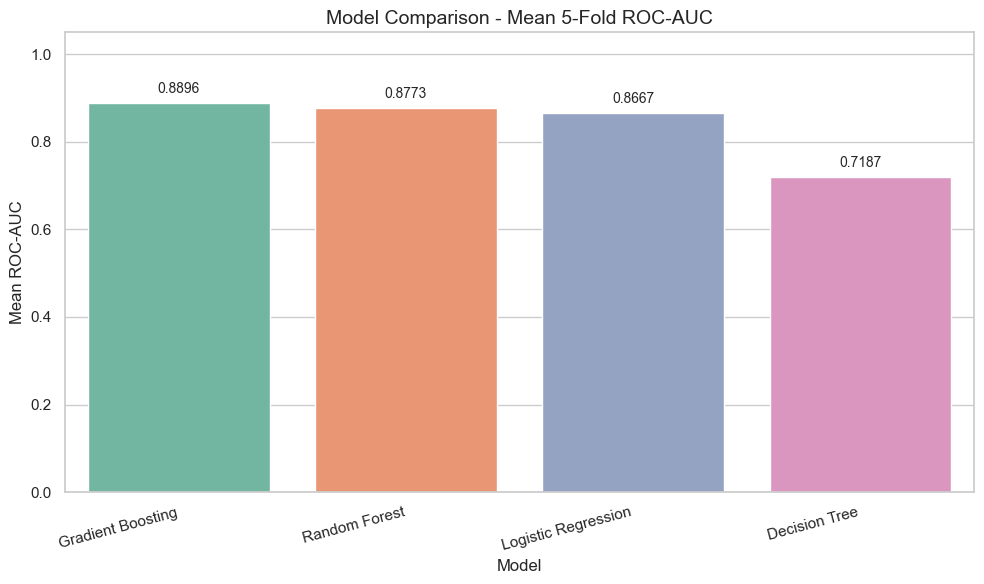

In [43]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Prepare the ROC-AUC comparison table
if "ROC-AUC" in cv_table.columns:
    plot_table = (
        cv_table.groupby("Model", as_index=False)["ROC-AUC"]
        .mean()
    )
elif "Mean ROC-AUC" in cv_table.columns:
    plot_table = cv_table[["Model", "Mean ROC-AUC"]].rename(
        columns={"Mean ROC-AUC": "ROC-AUC"}
    )
else:
    raise ValueError("ROC-AUC column not found in cv_table.")

plot_table = plot_table.sort_values("ROC-AUC", ascending=False)

# Create the bar chart
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=plot_table,
    x="Model",
    y="ROC-AUC",
    hue="Model",
    palette="Set2",
    legend=False
)

# Add the value above every bar
for bar in ax.patches:
    height = bar.get_height()
    if pd.notna(height):
        ax.annotate(
            f"{height:.4f}",
            (bar.get_x() + bar.get_width() / 2, height),
            ha="center",
            va="bottom",
            xytext=(0, 5),
            textcoords="offset points",
            fontsize=10
        )

plt.title("Model Comparison - Mean 5-Fold ROC-AUC", fontsize=14)
plt.xlabel("Model")
plt.ylabel("Mean ROC-AUC")
plt.ylim(0, 1.05)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


### Select the best model and evaluate it on the test set

In [44]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    roc_auc_score,
    confusion_matrix
)
import pandas as pd

# Step 1: Identify the correct ROC-AUC column
print("Available columns:", cv_table.columns.tolist())

if "Mean ROC-AUC" in cv_table.columns:
    # The table already contains one mean score per model
    model_comparison = (
        cv_table[["Model", "Mean ROC-AUC"]]
        .drop_duplicates(subset="Model")
        .sort_values("Mean ROC-AUC", ascending=False)
        .reset_index(drop=True)
    )

elif "ROC-AUC" in cv_table.columns:
    # The table contains individual scores for each fold
    model_comparison = (
        cv_table.groupby("Model", as_index=False)["ROC-AUC"]
        .mean()
        .rename(columns={"ROC-AUC": "Mean ROC-AUC"})
        .sort_values("Mean ROC-AUC", ascending=False)
        .reset_index(drop=True)
    )

else:
    raise ValueError(
        "ROC-AUC column not found. Check the available columns printed above."
    )

# Display the comparison and confirm the ranking
print("\nModel Comparison - Mean Cross-Validation ROC-AUC")
display(model_comparison.round(4))

# Step 2: Select the model with the highest mean ROC-AUC
best_model_name = model_comparison.loc[0, "Model"]
best_classifier = models[best_model_name]

print("\nSelected Best Model:", best_model_name)
print(
    "Mean ROC-AUC:",
    round(model_comparison.loc[0, "Mean ROC-AUC"], 4)
)

# Step 3: Create the pipeline using the selected model
best_pipeline = clone(baseline_pipeline).set_params(
    model=best_classifier
)

# Step 4: Train using the full training set
best_pipeline.fit(X_train_raw, y_train_pipeline)

# Step 5: Predict on the held-out test set
test_predictions = best_pipeline.predict(X_test_raw)
test_probabilities = best_pipeline.predict_proba(X_test_raw)[:, 1]

# Step 6: Evaluate test-set performance
print("\nTest Set Evaluation")
print(f"Test ROC-AUC: {roc_auc_score(y_test_pipeline, test_probabilities):.4f}")
print(f"Test Accuracy: {accuracy_score(y_test_pipeline, test_predictions) * 100:.2f}%")
print(
    f"Test Precision (Declined): "
    f"{precision_score(y_test_pipeline, test_predictions, zero_division=0) * 100:.2f}%"
)
print(
    f"Test Recall (Declined): "
    f"{recall_score(y_test_pipeline, test_predictions, zero_division=0) * 100:.2f}%"
)

# Step 7: Display the confusion matrix
test_cm = confusion_matrix(
    y_test_pipeline,
    test_predictions,
    labels=[0, 1]
)

test_cm_table = pd.DataFrame(
    test_cm,
    index=["Actual Approved", "Actual Declined"],
    columns=["Predicted Approved", "Predicted Declined"]
)

print("\nConfusion Matrix:")
display(test_cm_table)


Available columns: ['Model', 'Mean ROC-AUC', 'Mean Accuracy (%)', 'Mean Precision - Declined (%)', 'Mean Recall - Declined (%)']

Model Comparison - Mean Cross-Validation ROC-AUC


,Model,Mean ROC-AUC
0,Gradient Boosting,0.8896
1,Random Forest,0.8773
2,Logistic Regression,0.8667
3,Decision Tree,0.7187



Selected Best Model: Gradient Boosting
Mean ROC-AUC: 0.8896

Test Set Evaluation
Test ROC-AUC: 0.8853
Test Accuracy: 80.29%
Test Precision (Declined): 81.54%
Test Recall (Declined): 75.11%

Confusion Matrix:


,Predicted Approved,Predicted Declined
Actual Approved,1079,192
Actual Declined,281,848


### Plot the top eight feature importances

Top 8 Features: Gradient Boosting


,Feature,Importance
14,categorical__employment_type_Salaried,0.0158
3,numeric__loan_to_income,0.0162
13,categorical__employment_type_Gig / Contract,0.0172
1,numeric__is_ntc,0.0183
6,numeric__years_in_current_job,0.0289
2,numeric__foir,0.2864
0,numeric__credit_score,0.2872
4,numeric__delinquencies_24m,0.3078


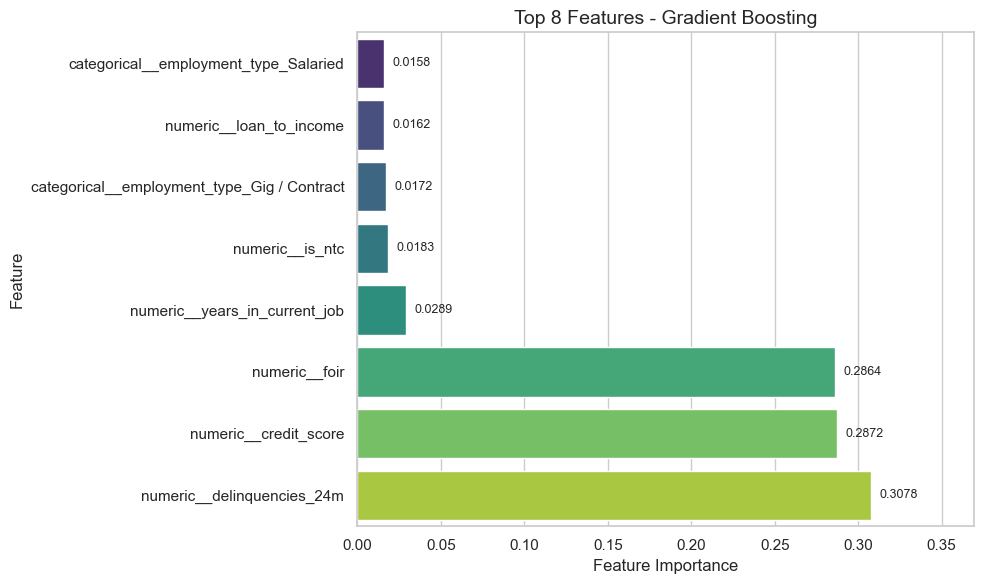

In [45]:

# Get feature names after preprocessing
processed_feature_names = (
    best_pipeline.named_steps["preprocessor"]
    .get_feature_names_out()
)

# Get importance values from the selected model
fitted_classifier = best_pipeline.named_steps["model"]

if hasattr(fitted_classifier, "feature_importances_"):
    importance_values = fitted_classifier.feature_importances_
    importance_label = "Feature Importance"
else:
    importance_values = np.abs(fitted_classifier.coef_[0])
    importance_label = "Absolute Coefficient"

# Create the feature importance table
importance_table = pd.DataFrame({
    "Feature": processed_feature_names,
    "Importance": importance_values
})

top_eight = importance_table.nlargest(
    8, "Importance"
).sort_values("Importance", ascending=True)

print("Top 8 Features:", best_model_name)
display(top_eight.round(4))

# Plot the top eight features
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=top_eight,
    x="Importance",
    y="Feature",
    hue="Feature",
    palette="viridis",
    legend=False,
    ax=ax
)

# Add a separate numerical label to every bar
for bar in ax.patches:
    value = bar.get_width()

    ax.text(
        value + 0.005,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.4f}",
        va="center",
        ha="left",
        fontsize=9
    )

plt.title(f"Top 8 Features - {best_model_name}", fontsize=14)
plt.xlabel(importance_label)
plt.ylabel("Feature")

# Leave enough space for all numerical labels
plt.xlim(0, top_eight["Importance"].max() * 1.20)

plt.tight_layout()
plt.show()


### Model Comparison — Interpretation

Based on five-fold stratified cross-validation on the training set, **Gradient Boosting** achieved the highest mean ROC-AUC of **0.8896**, compared with 0.8773 for Random Forest, 0.8667 for Logistic Regression, and 0.7187 for Decision Tree. Gradient Boosting also achieved a mean accuracy of 80.10%, mean precision of 81.38%, and mean recall of 74.88% for the Declined class. Therefore, it was selected for test-set evaluation.

On the test set, Gradient Boosting achieved a ROC-AUC of **0.8853**, accuracy of **80.29%**, precision of **81.54%** for the Declined class, and recall of **75.11%**. The confusion matrix shows that it correctly classified 1,079 approved applications and 848 declined applications. However, 192 approved applications were incorrectly classified as declined, while 281 declined applications were incorrectly classified as approved. These errors matter because wrongly declining suitable applicants can harm customers, while incorrectly approving risky applicants can expose the bank to credit losses.

The three leading features by importance were **delinquencies in the previous 24 months (0.3078)**, **credit score (0.2872)**, and **FOIR (0.2864)**. Together, these account for approximately 88.14% of the total feature importance. Other features among the top eight were years in the current job (0.0289), new-to-credit status (`is_ntc`, 0.0183), Gig / Contract employment (0.0172), loan-to-income ratio (0.0162), and Salaried employment (0.0158).

These results broadly agree with Steps 5.2 and 5.3. Step 5.2 examined how historical approval rates varied across credit-score bands, while Step 5.3 examined FOIR as an affordability measure. The high importance of credit score and FOIR supports examining these factors closely in credit screening. Delinquencies also emerged as the most important feature, highlighting the relevance of recent repayment history. However, feature importance shows how much a feature contributes to the model's predictions; it does not establish that a feature causes an approval or decline, nor does it by itself establish fairness.

Gradient Boosting's mean ROC-AUC was **0.0229 higher** than Logistic Regression's, indicating improved ability to distinguish between approved and declined applications. This improvement may justify using Gradient Boosting as the primary screening model, provided that the bank monitors errors, fairness, and decision explanations. Logistic Regression should remain a useful benchmark because its coefficients are generally easier to interpret. Since credit decisions need to be reviewed and explained, the bank should balance predictive performance with transparency and appropriate human oversight.

## 5.10  Design the two-lane pre-screener

### Search for the best threshold pairs

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone

# --------------------------------------------------
# Step 1: Prepare both models
# --------------------------------------------------

# Gradient Boosting is the selected model from Step 5.9.
gradient_boosting_pipeline = best_pipeline

# Fit Logistic Regression using the same training data.
logistic_pipeline = clone(baseline_pipeline).set_params(
    model=models["Logistic Regression"]
)
logistic_pipeline.fit(X_train_raw, y_train_pipeline)

model_pipelines = {
    "Gradient Boosting": gradient_boosting_pipeline,
    "Logistic Regression": logistic_pipeline
}

# Actual decisions: 0 = Approved, 1 = Declined
actual_decisions = np.asarray(y_test_pipeline)

# Get the probability of approval for each model.
# We identify the correct probability column using the model's class labels.
approval_probabilities = {}

for model_name, pipeline in model_pipelines.items():
    class_labels = pipeline.named_steps["model"].classes_
    approval_column = list(class_labels).index(0)

    approval_probabilities[model_name] = (
        pipeline.predict_proba(X_test_raw)[:, approval_column]
    )

# --------------------------------------------------
# Step 2: Search for the best low and high thresholds
# --------------------------------------------------

thresholds = np.arange(0.01, 1.00, 0.01)
best_results = []

for model_name, probabilities in approval_probabilities.items():

    best_candidate = None

    for low_threshold in thresholds:
        for high_threshold in thresholds:

            # The high threshold must be greater than the low threshold.
            if high_threshold <= low_threshold:
                continue

            # Auto-decline: probability of approval is below low threshold.
            auto_decline = probabilities < low_threshold

            # Fast-track: probability of approval is at or above high threshold.
            fast_track = probabilities >= high_threshold

            # All remaining applications require analyst review.
            analyst_review = ~(auto_decline | fast_track)

            # Count applications in each lane.
            auto_count = int(auto_decline.sum())
            fast_count = int(fast_track.sum())
            review_count = int(analyst_review.sum())

            # Avoid choosing thresholds that leave an automated lane empty.
            if auto_count == 0 or fast_count == 0:
                continue

            # Auto-decline error: applications actually approved by the
            # credit team that would have been auto-declined.
            auto_error = np.mean(actual_decisions[auto_decline] == 0)

            # Fast-track error: applications actually declined by the
            # credit team that would have been fast-tracked.
            fast_error = np.mean(actual_decisions[fast_track] == 1)

            # Keep only threshold pairs that satisfy BOTH risk limits.
            if auto_error <= 0.05 and fast_error <= 0.05:

                automated_count = auto_count + fast_count

                candidate = {
                    "Model": model_name,
                    "Low Threshold": low_threshold,
                    "High Threshold": high_threshold,
                    "Auto-decline": auto_count,
                    "Analyst review": review_count,
                    "Fast-track": fast_count,
                    "Auto-decline error (%)": auto_error * 100,
                    "Fast-track error (%)": fast_error * 100,
                    "Automated applications": automated_count
                }

                # Select the pair that moves the most applications
                # out of the analyst queue.
                if (
                    best_candidate is None
                    or automated_count >
                    best_candidate["Automated applications"]
                ):
                    best_candidate = candidate

    if best_candidate is not None:
        best_results.append(best_candidate)

# Show the selected threshold pair for each model.
results_table = pd.DataFrame(best_results)

if len(results_table) != 2:
    raise ValueError(
        "A valid threshold pair was not found for both models. "
        "Check the target encoding and model probability columns."
    )

display(results_table.round(2))

,Model,Low Threshold,High Threshold,Auto-decline,Analyst review,Fast-track,Auto-decline error (%),Fast-track error (%),Automated applications
0,Gradient Boosting,0.17,0.89,588,1356,456,4.59,4.61,1044
1,Logistic Regression,0.10,0.90,351,1679,370,4.27,4.05,721


### Plot the two-lane pre-screener

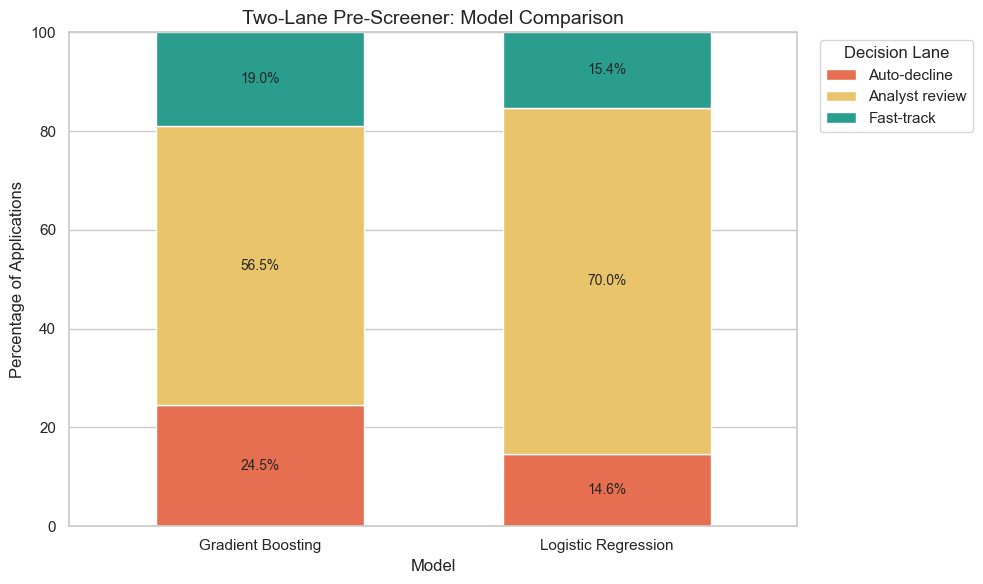

In [47]:
# Convert the number of applications in each lane into percentages.
lane_columns = ["Auto-decline", "Analyst review", "Fast-track"]

plot_data = results_table.set_index("Model")[lane_columns].copy()

plot_data = plot_data.div(plot_data.sum(axis=1), axis=0) * 100

# Plot the stacked bars.
ax = plot_data.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    color=["#E76F51", "#E9C46A", "#2A9D8F"],
    width=0.6
)

# Add percentage labels inside each segment when the segment is large enough.
for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%"
        if bar.get_height() >= 5 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=10)

plt.title("Two-Lane Pre-Screener: Model Comparison", fontsize=14)
plt.xlabel("Model")
plt.ylabel("Percentage of Applications")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Decision Lane", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

### Translate the result into monthly workload

In [48]:
# Monthly workload assumptions.
monthly_applications = 3000
minutes_per_review = 25

# Calculate the expected monthly volume and review hours for each model.
monthly_results = results_table[
    ["Model", "Auto-decline", "Analyst review", "Fast-track"]
].copy()

monthly_results["Auto-decline per month"] = (
    monthly_results["Auto-decline"] / len(y_test_pipeline)
    * monthly_applications
).round().astype(int)

monthly_results["Analyst reviews per month"] = (
    monthly_results["Analyst review"] / len(y_test_pipeline)
    * monthly_applications
).round().astype(int)

monthly_results["Fast-track per month"] = (
    monthly_results["Fast-track"] / len(y_test_pipeline)
    * monthly_applications
).round().astype(int)

monthly_results["Analyst hours per month"] = (
    monthly_results["Analyst reviews per month"]
    * minutes_per_review / 60
).round(1)

# Current workload if all applications receive manual review.
current_monthly_hours = monthly_applications * minutes_per_review / 60

monthly_results["Hours saved per month"] = (
    current_monthly_hours - monthly_results["Analyst hours per month"]
).round(1)

display(monthly_results)

,Model,Auto-decline,Analyst review,Fast-track,Auto-decline per month,Analyst reviews per month,Fast-track per month,Analyst hours per month,Hours saved per month
0,Gradient Boosting,588,1356,456,735,1695,570,706.2,543.8
1,Logistic Regression,351,1679,370,439,2099,462,874.6,375.4


### Generate the interpretation from your actual results

In [49]:
# Compare Gradient Boosting against Logistic Regression.
gb = monthly_results.loc[
    monthly_results["Model"] == "Gradient Boosting"
].iloc[0]

lr = monthly_results.loc[
    monthly_results["Model"] == "Logistic Regression"
].iloc[0]

gb_thresholds = results_table.loc[
    results_table["Model"] == "Gradient Boosting"
].iloc[0]

lr_thresholds = results_table.loc[
    results_table["Model"] == "Logistic Regression"
].iloc[0]

print(" Two-Lane Pre-Screener — Interpretation\n")

print(
    f"Gradient Boosting selected a low threshold of "
    f"{gb_thresholds['Low Threshold']:.2f} and a high threshold of "
    f"{gb_thresholds['High Threshold']:.2f}. "
    f"Its auto-decline error rate was "
    f"{gb_thresholds['Auto-decline error (%)']:.2f}% and its fast-track "
    f"error rate was {gb_thresholds['Fast-track error (%)']:.2f}%."
)

print(
    f"Logistic Regression selected a low threshold of "
    f"{lr_thresholds['Low Threshold']:.2f} and a high threshold of "
    f"{lr_thresholds['High Threshold']:.2f}. "
    f"Its auto-decline error rate was "
    f"{lr_thresholds['Auto-decline error (%)']:.2f}% and its fast-track "
    f"error rate was {lr_thresholds['Fast-track error (%)']:.2f}%."
)

print(
    f"\nAt {monthly_applications:,} applications per month, Gradient Boosting "
    f"would send approximately {gb['Analyst reviews per month']:,} "
    f"applications to analysts, compared with "
    f"{lr['Analyst reviews per month']:,} for Logistic Regression."
)

print(
    f"Gradient Boosting would save approximately "
    f"{gb['Hours saved per month']:.1f} analyst hours per month, "
    f"compared with {lr['Hours saved per month']:.1f} hours for "
    f"Logistic Regression, assuming {minutes_per_review} minutes per review."
)

print(
    "\nBoth threshold pairs satisfy the specified 5% lane-error limits "
    "on this evaluation sample. The model with fewer analyst reviews "
    "provides the larger estimated reduction in manual workload. "
    "These estimates should be confirmed on separate validation data "
    "before implementation."
)

 Two-Lane Pre-Screener — Interpretation

Gradient Boosting selected a low threshold of 0.17 and a high threshold of 0.89. Its auto-decline error rate was 4.59% and its fast-track error rate was 4.61%.
Logistic Regression selected a low threshold of 0.10 and a high threshold of 0.90. Its auto-decline error rate was 4.27% and its fast-track error rate was 4.05%.

At 3,000 applications per month, Gradient Boosting would send approximately 1,695 applications to analysts, compared with 2,099 for Logistic Regression.
Gradient Boosting would save approximately 543.8 analyst hours per month, compared with 375.4 hours for Logistic Regression, assuming 25 minutes per review.

Both threshold pairs satisfy the specified 5% lane-error limits on this evaluation sample. The model with fewer analyst reviews provides the larger estimated reduction in manual workload. These estimates should be confirmed on separate validation data before implementation.


### Two-Lane Pre-Screener — Interpretation

The two-lane pre-screener uses separate low and high approval-probability thresholds. Applications below the low threshold enter the auto-decline lane, applications above the high threshold enter the fast-track lane, and all remaining applications go to analyst review.

Threshold pairs were searched for both Gradient Boosting and Logistic Regression. The selected pairs were required to keep the proportion of historically approved applicants in the auto-decline lane at or below 5%, and the proportion of historically declined applicants in the fast-track lane at or below 5%.

At an assumed monthly volume of 3,000 applications, Gradient Boosting is estimated to require **1,695 manual reviews** and save **543.8 analyst hours per month**. Logistic Regression is estimated to require **2,099 manual reviews** and save **375.4 analyst hours per month**.

The stacked bar chart compares how the two models distribute applications across auto-decline, analyst review and fast-track. Gradient Boosting reduces the manual review workload more than Logistic Regression while meeting both specified risk limits on this evaluation sample. However, explainability and fairness must also be considered. These estimates should be validated on separate data before the thresholds are used in real credit decisions.

In [50]:
# Calculate each lane's share of the test applications.
lane_columns = ["Auto-decline", "Analyst review", "Fast-track"]

lane_percentages = results_table[["Model"] + lane_columns].copy()

lane_percentages[lane_columns] = (
    lane_percentages[lane_columns]
    .div(results_table[lane_columns].sum(axis=1), axis=0)
    * 100
)

display(lane_percentages.round(2))

,Model,Auto-decline,Analyst review,Fast-track
0,Gradient Boosting,24.50,56.50,19.00
1,Logistic Regression,14.62,69.96,15.42


## 5.11 Your Recommendation to the Credit Policy Analyst

### Credit Policy Recommendation

I recommend piloting the **Gradient Boosting model** with a low threshold of **0.17 for auto-decline** and a high threshold of **0.89 for fast-track**, as both lanes met the specified 5% error limits on the evaluation sample. Gradient Boosting would route approximately **24.50%** of applications to auto-decline, **56.50%** to analyst review, and **19.00%** to fast-track, compared with 14.62%, 69.96%, and 15.42%, respectively, for Logistic Regression. At a monthly volume of 3,000 applications, Gradient Boosting is estimated to require **1,695 manual reviews and save 543.8 analyst hours**, compared with 2,099 reviews and 375.4 hours saved using Logistic Regression. This represents approximately **404 fewer manual reviews and 168.4 additional analyst hours saved per month** with Gradient Boosting. The main risks are wrongly declining creditworthy applicants and fast-tracking applicants who should be declined, so borderline cases, applicants with missing or limited credit histories, and applications flagged by affordability or fairness checks should remain subject to human review. The bank should provide explainable reasons for decisions, maintain an appropriate review process, and monitor approval, lane allocation, and error rates across gender and employment groups because excluding gender from the model does not guarantee fairness. Before full rollout, I recommend a **shadow-mode pilot** in which the model assigns application lanes without affecting actual lending decisions. During this pilot, the bank should compare predictions with analyst decisions, verify that both error rates remain within the 5% limits on new applications, monitor fairness, and confirm that the expected workload savings are sustained.

## 5.12  Stretch : Where does the model struggle?

Need to group applicants into segments using K-Means, understand each segment's approval rate, and check where your selected Gradient Boosting model makes the most errors.

Elbow plot — to help choose the number of clusters.



Cluster size bar chart — to compare how many applicants belong to each segment.



Approval rate by segment — to identify segments with higher and lower approval rates.



Model error rate by segment on the test set — to identify which segment needs more human review.

### Select the clustering features

K-Means clustering is used to group applicants with similar financial and personal characteristics. The five features used are monthly income, credit score, FOIR, years in the current job, and age.

The clusters help identify applicant groups that may require additional attention. Cluster labels are used only for analysis and are not included as inputs to the predictive model.

In [51]:
# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Select the five features required by the assignment
cluster_features = [
    "monthly_income",
    "credit_score",
    "foir",
    "years_in_current_job",
    "age"
]

# Create FOIR if it is not already available in df_features
if "foir" not in df_features.columns:
    df_features["foir"] = (
        df_features["existing_emi"] + df_features["proposed_emi"]
    ) / df_features["monthly_income"].replace(0, np.nan)

# Copy the clustering features
cluster_data = df_features[cluster_features].copy()

# Convert all selected columns to numeric values
for col in cluster_features:
    cluster_data[col] = pd.to_numeric(
        cluster_data[col], errors="coerce"
    )

# Replace infinite values with missing values
cluster_data = cluster_data.replace([np.inf, -np.inf], np.nan)

# Impute missing values and scale features before clustering
cluster_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare the scaled data
scaled_cluster_data = cluster_preprocessor.fit_transform(cluster_data)

print("Clustering data prepared successfully.")
print("Number of applications:", len(cluster_data))
print("Features used:", cluster_features)

Clustering data prepared successfully.
Number of applications: 12000
Features used: ['monthly_income', 'credit_score', 'foir', 'years_in_current_job', 'age']


### Draw the elbow plot

,Number of Clusters,Inertia
0,2,48667.68
1,3,43213.84
2,4,38370.04
3,5,33928.51
4,6,30719.49
5,7,28827.17
6,8,27625.53


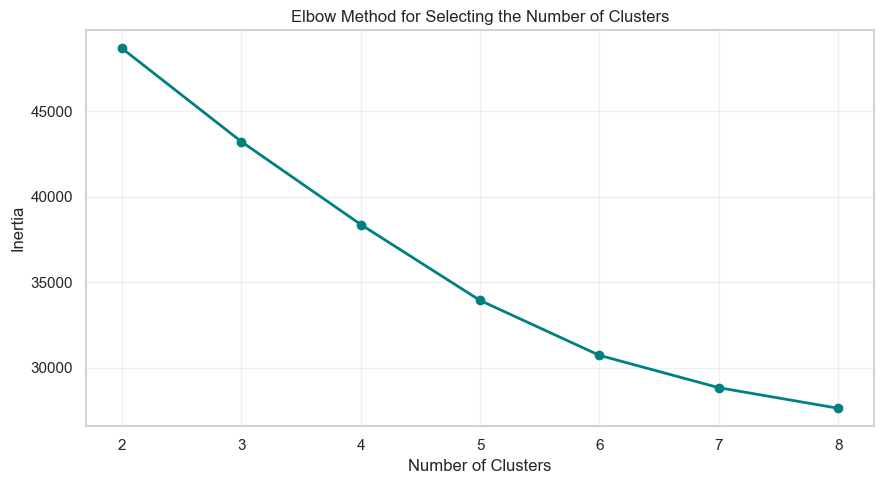

In [52]:
# Calculate inertia for different numbers of clusters
inertia_values = []

cluster_range = range(2, 9)

for k in cluster_range:
    kmeans_test = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans_test.fit(scaled_cluster_data)
    inertia_values.append(kmeans_test.inertia_)

# Display the inertia values
elbow_results = pd.DataFrame({
    "Number of Clusters": list(cluster_range),
    "Inertia": inertia_values
})

display(elbow_results.round(2))

# Plot the elbow curve
plt.figure(figsize=(9, 5))

plt.plot(
    list(cluster_range),
    inertia_values,
    marker="o",
    linewidth=2,
    color="teal"
)

plt.title("Elbow Method for Selecting the Number of Clusters")
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.xticks(list(cluster_range))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

How to choose four clusters: Look for the point where the curve starts flattening and adding more clusters produces smaller improvements. If the elbow is around \(k=4\), four clusters are a reasonable choice. Do not claim the plot proves four is the only correct choice.

### Fit K-Means with four clusters

In [53]:
# Choose four clusters based on the elbow plot
chosen_k = 4

# Fit the final K-Means model
kmeans_model = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

# Assign a cluster ID to every application
cluster_labels = kmeans_model.fit_predict(scaled_cluster_data)

# Store the cluster IDs against the original row indexes
segment_ids = pd.Series(
    cluster_labels,
    index=df_features.index,
    name="Segment ID"
)

# Add segment IDs to a separate analysis DataFrame
segment_data = df_features.copy()
segment_data["Segment ID"] = segment_ids

print("K-Means clustering completed.")
print("\nNumber of applicants in each segment:")

display(
    segment_data["Segment ID"]
    .value_counts()
    .sort_index()
    .rename("Applicants")
    .to_frame()
)

K-Means clustering completed.

Number of applicants in each segment:


,Applicants
Segment ID,
0,1736
1,5916
2,2599
3,1749


### Create segment profiles and assign business names

Rather than assuming that a cluster number means a particular risk category, this cell examines the actual average income, credit score, FOIR, and job tenure before assigning descriptive names.

In [54]:
# Calculate the average characteristics of each segment
segment_profiles = (
    segment_data.groupby("Segment ID")[cluster_features]
    .mean()
)

# Calculate the historical approval rate for each segment
segment_data["decision_clean"] = (
    segment_data["decision"]
    .astype("string")
    .str.strip()
    .str.lower()
)

segment_data["is_approved"] = (
    segment_data["decision_clean"] == "approved"
).astype(int)

approval_rates = (
    segment_data.groupby("Segment ID")["is_approved"]
    .mean()
    .mul(100)
    .rename("Approval Rate (%)")
)

# Combine the profiles and approval rates
segment_profiles = segment_profiles.join(approval_rates)

# Assign names based on the observed profiles
# Highest FOIR: greatest affordability concern
high_foir_id = segment_profiles["foir"].idxmax()

# Highest income: higher-income applicant group
high_income_id = segment_profiles["monthly_income"].idxmax()

# The two remaining clusters are distinguished by job tenure
remaining_ids = [
    segment_id
    for segment_id in segment_profiles.index
    if segment_id not in [high_foir_id, high_income_id]
]

established_id = (
    segment_profiles.loc[remaining_ids, "years_in_current_job"]
    .idxmax()
)

shorter_tenure_id = next(
    segment_id
    for segment_id in remaining_ids
    if segment_id != established_id
)

# Map numeric IDs to descriptive business names
segment_name_map = {
    high_foir_id: "High FOIR / Affordability Risk",
    high_income_id: "Higher-Income Applicants",
    established_id: "Established Employment",
    shorter_tenure_id: "Moderate Income / Shorter Tenure"
}

# Apply the same names to the profile table
segment_profiles["Segment Name"] = (
    segment_profiles.index.map(segment_name_map)
)

# Display the segment profiles
display(
    segment_profiles[
        [
            "Segment Name",
            "monthly_income",
            "credit_score",
            "foir",
            "years_in_current_job",
            "age",
            "Approval Rate (%)"
        ]
    ].round(2)
)

,Segment Name,monthly_income,credit_score,foir,years_in_current_job,age,Approval Rate (%)
Segment ID,,,,,,,
0,Higher-Income Applicants,120869.96,728.67,0.32,3.63,35.92,59.22
1,Moderate Income / Shorter Tenure,44977.86,714.37,0.29,2.35,29.41,53.50
2,Established Employment,55907.27,743.08,0.31,7.59,39.50,67.76
3,High FOIR / Affordability Risk,51723.27,734.34,0.72,3.05,33.65,22.81


### Calculate test-set error rates by segment

In [55]:
# Get the test applications' cluster IDs
test_segment_ids = segment_ids.loc[X_test_raw.index]

# Generate predictions using the already fitted Gradient Boosting pipeline
gb_test_predictions = gradient_boosting_pipeline.predict(X_test_raw)

# Compare predictions with the actual test labels
test_evaluation = pd.DataFrame(index=X_test_raw.index)

test_evaluation["Segment ID"] = test_segment_ids
test_evaluation["Actual Decision"] = y_test_pipeline.loc[X_test_raw.index]
test_evaluation["Predicted Decision"] = gb_test_predictions

# Error = prediction does not match the actual decision
test_evaluation["Model Error"] = (
    test_evaluation["Actual Decision"]
    != test_evaluation["Predicted Decision"]
).astype(int)

# Summarise test applicants and error rates by segment
test_segment_summary = (
    test_evaluation.groupby("Segment ID")
    .agg(
        Test_Applicants=("Model Error", "size"),
        Test_Errors=("Model Error", "sum"),
        Test_Error_Rate=("Model Error", "mean")
    )
)

test_segment_summary["Test_Error_Rate (%)"] = (
    test_segment_summary["Test_Error_Rate"] * 100
)

# Count all applications in each segment
segment_summary = (
    segment_data.groupby("Segment ID")
    .agg(
        Applicants=("Segment ID", "size"),
        Approval_Rate=("is_approved", "mean")
    )
)

segment_summary["Approval_Rate (%)"] = (
    segment_summary["Approval_Rate"] * 100
)

# Combine the full-segment and test-set results
segment_summary = segment_summary.join(test_segment_summary)

# Add descriptive names
segment_summary["Segment Name"] = (
    segment_summary.index.map(segment_name_map)
)

# Show the final summary
segment_summary = segment_summary[
    [
        "Segment Name",
        "Applicants",
        "Approval_Rate (%)",
        "Test_Applicants",
        "Test_Errors",
        "Test_Error_Rate (%)"
    ]
]

display(segment_summary.round(2))

,Segment Name,Applicants,Approval_Rate (%),Test_Applicants,Test_Errors,Test_Error_Rate (%)
Segment ID,,,,,,
0,Higher-Income Applicants,1736,59.22,333,87,26.13
1,Moderate Income / Shorter Tenure,5916,53.50,1166,236,20.24
2,Established Employment,2599,67.76,536,98,18.28
3,High FOIR / Affordability Risk,1749,22.81,365,52,14.25


### Plot all three segment charts using business names

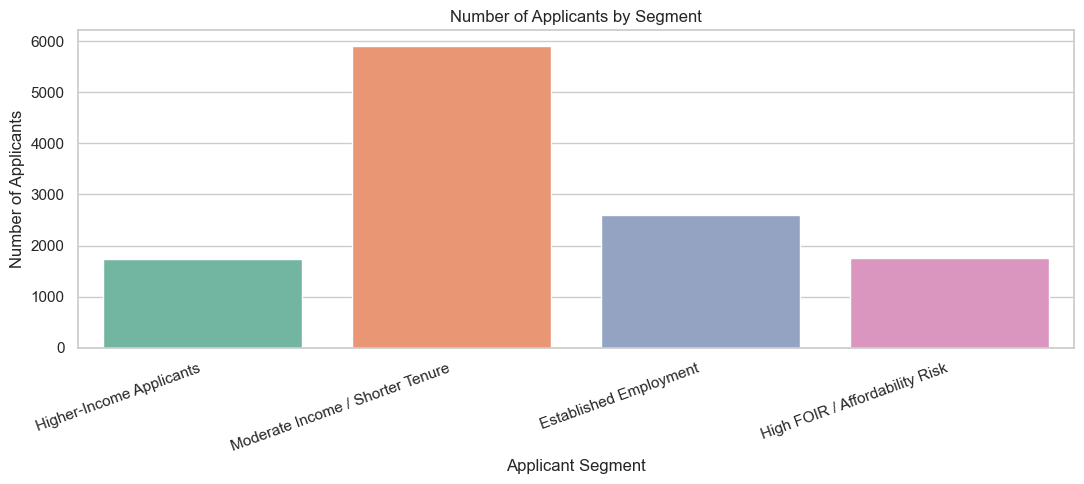

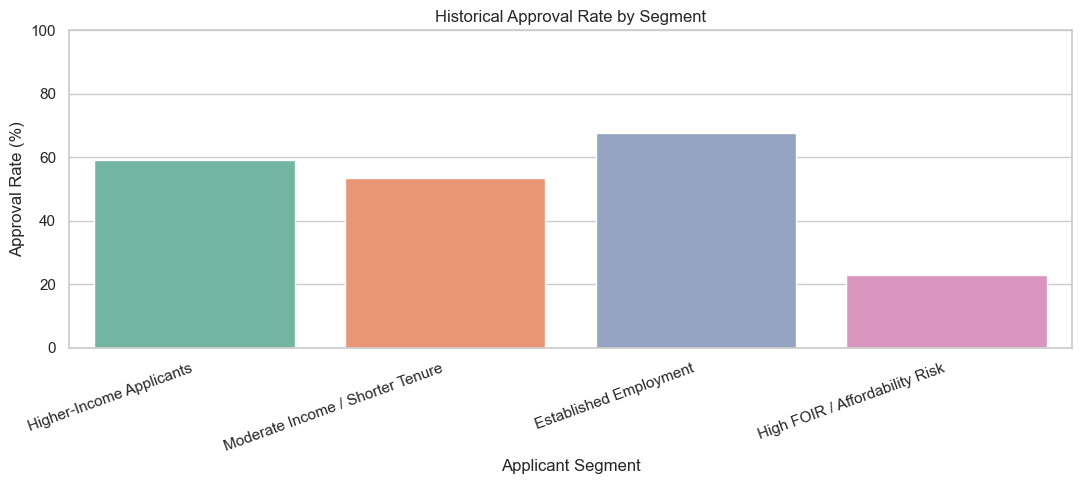

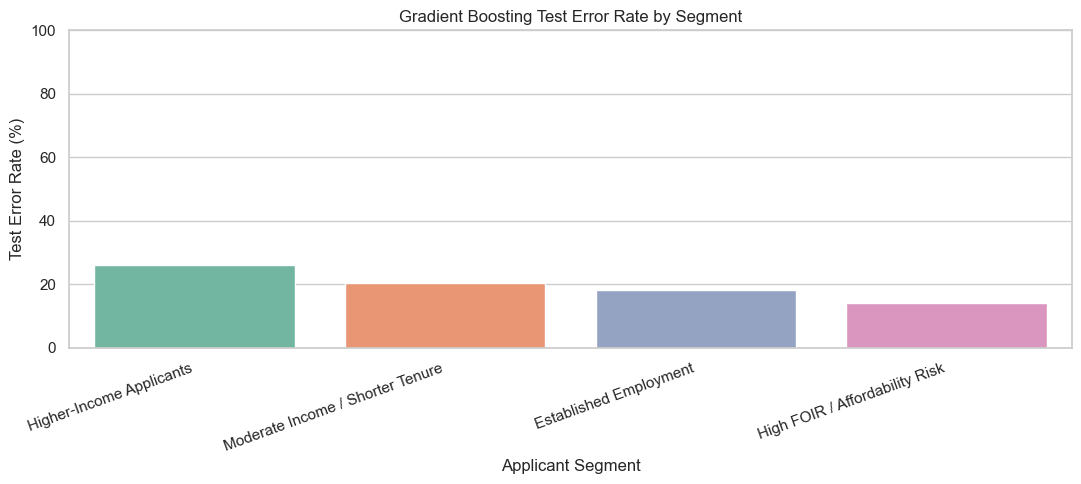

In [56]:
# Prepare a plotting table
plot_data = segment_summary.reset_index()

# Chart 1: Number of applicants in each segment
plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="Segment Name",
    y="Applicants",
    hue="Segment Name",
    palette="Set2",
    legend=False
)

plt.title("Number of Applicants by Segment")
plt.xlabel("Applicant Segment")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# Chart 2: Historical approval rate by segment
plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="Segment Name",
    y="Approval_Rate (%)",
    hue="Segment Name",
    palette="Set2",
    legend=False
)

plt.title("Historical Approval Rate by Segment")
plt.xlabel("Applicant Segment")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


# Chart 3: Gradient Boosting test error rate by segment
plt.figure(figsize=(11, 5))

sns.barplot(
    data=plot_data,
    x="Segment Name",
    y="Test_Error_Rate (%)",
    hue="Segment Name",
    palette="Set2",
    legend=False
)

plt.title("Gradient Boosting Test Error Rate by Segment")
plt.xlabel("Applicant Segment")
plt.ylabel("Test Error Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### Identify the segment with the highest test error

In [57]:
# Find the segment with the highest test error rate
highest_error_segment = segment_summary[
    "Test_Error_Rate (%)"
].idxmax()

highest_error_name = segment_summary.loc[
    highest_error_segment, "Segment Name"
]

highest_error_rate = segment_summary.loc[
    highest_error_segment, "Test_Error_Rate (%)"
]

print("Segment needing the closest model-error review:")
print(highest_error_name)
print(f"Test error rate: {highest_error_rate:.2f}%")

# Find the segment with the highest average FOIR
highest_foir_segment = segment_profiles["foir"].idxmax()

print("\nSegment with the highest average FOIR:")
print(segment_name_map[highest_foir_segment])
print(
    f"Average FOIR: "
    f"{segment_profiles.loc[highest_foir_segment, 'foir']:.2f}"
)

Segment needing the closest model-error review:
Higher-Income Applicants
Test error rate: 26.13%

Segment with the highest average FOIR:
High FOIR / Affordability Risk
Average FOIR: 0.72


### Segment Analysis — Interpretation

K-Means grouped applicants using monthly income, credit score, FOIR, years in the current job, and age. The elbow plot helped assess whether four clusters were a reasonable choice. Each segment was examined using its size, historical approval rate, and Gradient Boosting test error rate.

The **Higher-Income Applicants** segment had the highest test error rate at **26.13%**. This means the model made a larger proportion of incorrect predictions for this group than for the other segments. The bank should investigate these errors before relying on model predictions for this group.

The **High FOIR / Affordability Risk** segment had the highest average FOIR at **0.72**, meaning that existing and proposed EMIs account for approximately 72% of monthly income on average. This indicates a high repayment burden and supports further affordability checks. However, applicants should not be declined solely because they belong to a particular cluster.

These segments are useful for identifying groups that may need closer examination. The bank should review both affordability concerns and model errors, and validate these findings on new applications before using them in real lending decisions.